# Машинное обучение

# Тема 2. Разведывательный анализ данных (EDA)

* [1. Описательные статистики](#chapter1) 
* [2. Сводные таблицы и группировки](#chapter2)
* [3. Частотный анализ данных](#chapter3)
* [4. Графический анализ данных](#chapter4)
* [5. Таблицы сопряжённости](#chapter5)
* [6. Корреляционный анализ](#chapter6)

In [1]:
#pip install pingouin
#pip install wordcloud

import pandas as pd  # работа с табличными данными и их анализ
from scipy import stats  # статистические тесты и функции
from math import sqrt  # вычисление квадратного корня
from scipy.stats import chi2_contingency  # Хи-квадрат
import matplotlib.pyplot as plt  # построение графиков и визуализация
import seaborn as sns  # продвинутые статистические визуализации
from scipy.stats import pointbiserialr # корреляция для бинарных данных 
from scipy.stats import norm  # нормальное распределение
import numpy as np  # работа с массивами и числовыми операциями
from wordcloud import WordCloud  # облако слов
import pingouin as pg  # Q-Q Plot и частная корреляция
import warnings
warnings.filterwarnings('ignore')  # отключаем предупреждения для чистого вывода

С портала [Работа России](https://trudvsem.ru/opendata/datasets) взят датасет с вакансиями по всем регионам России из ЕЦП «Работа в России» по состоянию на сентябрь 2026 года. Ниже описание признаков из датасета. Описание с официального сайта и охватывает не все признаки, фактически представленные в датасете.

| № | Название признака | Назначение | Описание |
|---|------------------------------|------------|----------|
| 1 | vacancyName | Наименование вакансии | Наименование вакансии |
| 2 | codeProfession | Код профессии | Код профессии из справочника профессий dict_profession (поле code) |
| 3 | codeProfessionalSphere | Код профессиональной сферы | Код (англоязычное название) профессиональной сферы из справочника dict_professional_sphere (поле code) |
| 4 | professionalSphereName | Наименование профессиональной сферы | Наименование (англоязычное название) профессиональной сферы из справочника dict_professional_sphere (поле name) |
| 5 | salary | Заработная плата | salaryMin – минимальный размер; salaryMax – максимальный размер |
| 6 | socialProtecteds | Группа соц. защищенности | socialProtectedIds (id), socialProtected (name) из dict_social_protected |
| 7 | languageKnowledge | Знание языков | codeLanguage, idOwner, isModerated, isPreferred, level, type |
| 8 | busyType | Тип занятости | FULL, PARTIAL, PROJECT, PROBATION, SEASONAL, REMOTE |
| 9 | educationRequirements | Требования к образованию | NULL, MIDDLE, MIDDLE_SPECIAL, UNFINISHED_HIGH, HIGH |
|10 | speciality | Специалитет | — |
|11 | academicDegree | Ученая степень | — |
|12 | hardSkills | Профессиональные навыки | hardSkillName |
|13 | softSkills | Гибкие навыки | hardSkillName |
|14 | experienceRequirements | Требуемый опыт | Количество лет |
|15 | qualifications | Квалификация | Степень и уровень проф. подготовленности |
|16 | professionalSphereName | Наименование профессиональной сферы | dict_professional_sphere (external_id) |
|17 | scheduleType | График работы | FULL, TURN, FLOAT, WATCH, IRREGULAR, PART_TIME |
|18 | premium | Премия | premiumSize, premiumType (ANNUAL, QUARTERLY, MONTHLY), bonusType (RUB, PERCENT) |
|19 | otherVacancyBenefit | Дополнительные бонусы | Заполняется вручную |
|20 | id | Идентификатор вакансии | Идентификатор вакансии |
|21 | careerPerspective | Карьерный рост | true / false |
|22 | codeExternalSystem | Код внешней системы | SKILLSNET, CZN, ABILYMPICS, ENUM, RESUME, TEMPLATE |
|23 | idPriorityCategory | Категория приоритетности | Признак «Опытные кадры» (true / false) |
|24 | needMedcard | Медицинская книжка | требуется / не требуется / не указано |
|25 | sourceType | Тип источника вакансии | RECRUITMENT_AGENCY, COMPANY, CHAZ, EMPLOYMENT_SERVICE, HR_SERVICE, RPORTAL, FROM_ESIA, INTERNET_RESOURCE |
|26 | requiredCertificates | Сертификаты | Заполняется вручную |
|27 | requiredDriveLicense | Водительские права | A, B, C, D, E |
|28 | retrainingCapability | Возможность переобучения | true / false |
|29 | retrainingCondition | Условия переобучения | Текстовое поле |
|30 | retrainingGrantValue | Оплата во время обучения | Да |
|31 | transportCompensation | Транспортные расходы | FUEL_PAID, PASSAGE_PAID, AUTO |
|32 | changeTime | Время изменения | ГГГГ-ММ-ДД ЧЧ:ММ:СС |
|33 | contactPerson | Контактное лицо | ФИО |
|34 | contactSource | Источник контактов | — |
|35 | company | Информация о компании | code, inn, email, phone, site, ogrn и др. |
|36 | fullCompanyName | Полное наименование компании | — |
|37 | oknpoCode | ОКНПО | — |
|38 | oksoCode | ОКСО | — |
|39 | companyBusinessSize | Размер компании | SMALL, MICRO, MIDDLE, BIG, LARGE |
|40 | dateModify | Дата изменения | ГГГГ-ММ-ДД ЧЧ:ММ:СС |
|41 | workPlaces | Рабочие места | Количество |
|42 | isUzbekistanRecruitment | Оргнабор Узбекистан | true / false |
|43 | federalDistrictCode | Федеральный округ | Код |
|44 | industryBranchName | Отрасль | dict_industry_branch |
|45 | datePublished | Дата публикации | ГГГГ-ММ-ДД |
|46 | accommodationCapability | Возможность переезда | true / false / не указано |
|47 | accommodationType | Тип жилья | NULL, FLAT, ROOM, DORMITORY, HOUSE |
|48 | foreignWorkersCapability | Найм нерезидентов | true / false |
|49 | isQuoted | Квотируемая вакансия | true / false |
|50 | creationDate | Дата создания | ГГГГ-ММ-ДД ЧЧ:ММ:СС |
|51 | deleted | Признак удаления | true / false |
|52 | visibility | Видимость | HIDDEN, VISIBLE_TO_ALL |
|53 | regionName | Регион | — |
|54 | status | Статус вакансии | WAITING, ACCEPTED, CHANGED, REJECTED |
|55 | vacancyUrl | Ссылка на вакансию | URL |
|56 | positionRequirements | Должностные требования | Текст |
|57 | isMobilityProgram | Программа мобильности | true / false |
|58 | isModerated | Модерация | true / false |
|59 | metroIds | Станции метро | dict_metro |
|60 | vacancyAddress | Адрес | Область, город |
|61 | vacancyAddressHouse | Дом | — |
|62 | vacancyAddressAdditionalInfo | Адрес (доп.) | Доп. информация |
|63 | geo | Геокоординаты | longitude, latitude |


Прочитаем содержимое файла. Выяснилось, что в файле есть проблемные строки, будем их пропускать. В файле используется нестандартный разделитель '|' (обычно запятая), укажем это в параметрах функции read_csv(). Файл довольно большой, может считываться до минуты.

In [2]:
df = pd.read_csv('vacancy.csv', sep='|', on_bad_lines='skip')

Посмотрим на данные. 

In [3]:
df

,id,stateRegionCode,vacancyName,codeProfession,codeProfessionalSphere,professionalSphereName,vacancyAddress,vacancyAddressHouse,vacancyAddressAdditionalInfo,geo,...,hireDate,workPlace,medicalCertificate,scheduleTypeComment,benefitDetails,trainingDays,shift,medicalDocument,benefit,conditions
0,d301be38-6f11-11f1-90b8-c7c4ad68b305,6100000000000,Подсобный рабочий,167711.0,NotQualification,"Работы, не требующие квалификации","Ростовская область, Город Донецк, Шевченко ули...",6,NaN,{},...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,NaN,0.0,[],NaN,NaN,NaN
1,6943ef2d-210c-11f1-9ac8-d164183f71d4,9100000000000,Помощник воспитателя,168447.0,Medicine,Здравоохранение и социальное обеспечение,"Республика Крым, Город Алушта, Партенит посело...",дом: Д. 1;,NaN,"{""latitude"": 44.579307, ""longitude"": 34.342872}",...,2026-03-23T03:00:00+0300,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,NaN,0.0,[],Медицинская книжка,NaN,Оптимальные
2,947eb3e4-6eba-11f1-a924-e59c955c822f,4300000000000,"Продавец (Киров, Торфяная, 6)",NaN,Sales,"Продажи, закупки, снабжение, торговля","Кировская область, Город Киров",NaN,Торфяная 6,"{""latitude"": 58.603595, ""longitude"": 49.668023}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,NaN,0.0,[],NaN,NaN,NaN
3,7bd33540-1e58-11f0-b6d4-cb26dff57dd7,3800000000000,"Водитель автомобиля, военный комиссариат (горо...",114428.0,NotQualification,"Работы, не требующие квалификации","Иркутская область, Город Ангарск, 17 микрорайо...",13,NaN,"{""latitude"": 52.496126, ""longitude"": 103.85181}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,NaN,0.0,[],NaN,NaN,Оптимальные
4,13b70b08-21bb-11f1-a132-1bfbe2e9d3d5,7000000000000,Электромонтер по эксплуатации распределительны...,198673.0,ElectricpowerIndustry,Электроэнергетика,"Томская область, Асиновский район, Город Асино...",3,"636841, г Асино, р-н Асиновский","{""latitude"": 56.995725, ""longitude"": 86.148058}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,NaN,0.0,[],NaN,"Оплата занятий спортом,Добровольное медицинско...",Вредные
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
511463,edb5b774-8408-11f1-aff0-c55f97f117a7,7800000000000,"Продавец (Санкт-Петербург, проспект Стачек, 75)",NaN,Sales,"Продажи, закупки, снабжение, торговля",Город Санкт-Петербург,NaN,проспект Стачек 75,"{""latitude"": 59.938676, ""longitude"": 30.314494}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,NaN,0,[],NaN,NaN,NaN
511464,edb58dcb-958a-11f1-9253-c35c7c22d563,100000000000,Электромонтер по эксплуатации электросчетчиков...,105538.0,ElectricpowerIndustry,Электроэнергетика,"Республика Адыгея (Адыгея), Город Майкоп, Шовг...",358,рабочее место: Майкоп,"{""latitude"": 44.629794, ""longitude"": 40.124932}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,- материальная помощь в различных жизненных си...,0,[],Медицинская книжка,"Иное,Добровольное медицинское страхование,Опла...",Допустимые
511465,edb3e66a-2397-11f1-8ad2-c1033fd9106c,3600000000000,Оператор заправочных станций,103147.0,Sales,"Продажи, закупки, снабжение, торговля","Воронежская область, Рамонский район, Л3 терри...",1,"Воронежская обл., Рамонский р-н, 482+600 км вл...","{""latitude"": 51.929141, ""longitude"": 39.186651}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,"Расширенный социальный пакет, ДМС, страхование...",0,"[""По графику сменности""]",NaN,"Оплата занятий спортом,Иное,Добровольное медиц...",NaN
511466,edb052c8-6fdc-11f1-8e75-9d7d14c7bdd4,1600000000000,Заведующий складом,201150.0,Culture,"Искусство, культура и развлечения","Республика Татарстан (Татарстан), Город Казань...",57,"Первый этаж, вход через колонны","{""latitude"": 55.781464, ""longitude"": 49.133256}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,NaN,0,[],NaN,NaN,Допустимые


In [4]:
df.head()  # отобразить первые пять записей

,id,stateRegionCode,vacancyName,codeProfession,codeProfessionalSphere,professionalSphereName,vacancyAddress,vacancyAddressHouse,vacancyAddressAdditionalInfo,geo,...,hireDate,workPlace,medicalCertificate,scheduleTypeComment,benefitDetails,trainingDays,shift,medicalDocument,benefit,conditions
0,d301be38-6f11-11f1-90b8-c7c4ad68b305,6100000000000,Подсобный рабочий,167711.0,NotQualification,"Работы, не требующие квалификации","Ростовская область, Город Донецк, Шевченко ули...",6,NaN,{},...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,NaN,0.0,[],NaN,NaN,NaN
1,6943ef2d-210c-11f1-9ac8-d164183f71d4,9100000000000,Помощник воспитателя,168447.0,Medicine,Здравоохранение и социальное обеспечение,"Республика Крым, Город Алушта, Партенит посело...",дом: Д. 1;,NaN,"{""latitude"": 44.579307, ""longitude"": 34.342872}",...,2026-03-23T03:00:00+0300,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,NaN,0.0,[],Медицинская книжка,NaN,Оптимальные
2,947eb3e4-6eba-11f1-a924-e59c955c822f,4300000000000,"Продавец (Киров, Торфяная, 6)",NaN,Sales,"Продажи, закупки, снабжение, торговля","Кировская область, Город Киров",NaN,Торфяная 6,"{""latitude"": 58.603595, ""longitude"": 49.668023}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,NaN,0.0,[],NaN,NaN,NaN
3,7bd33540-1e58-11f0-b6d4-cb26dff57dd7,3800000000000,"Водитель автомобиля, военный комиссариат (горо...",114428.0,NotQualification,"Работы, не требующие квалификации","Иркутская область, Город Ангарск, 17 микрорайо...",13,NaN,"{""latitude"": 52.496126, ""longitude"": 103.85181}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,NaN,0.0,[],NaN,NaN,Оптимальные
4,13b70b08-21bb-11f1-a132-1bfbe2e9d3d5,7000000000000,Электромонтер по эксплуатации распределительны...,198673.0,ElectricpowerIndustry,Электроэнергетика,"Томская область, Асиновский район, Город Асино...",3,"636841, г Асино, р-н Асиновский","{""latitude"": 56.995725, ""longitude"": 86.148058}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,NaN,0.0,[],NaN,"Оплата занятий спортом,Добровольное медицинско...",Вредные


In [5]:
df.tail(7)  # отобразить последние 7 записей

,id,stateRegionCode,vacancyName,codeProfession,codeProfessionalSphere,professionalSphereName,vacancyAddress,vacancyAddressHouse,vacancyAddressAdditionalInfo,geo,...,hireDate,workPlace,medicalCertificate,scheduleTypeComment,benefitDetails,trainingDays,shift,medicalDocument,benefit,conditions
511461,edc3e214-50e0-11f1-8888-2d6765da1e37,6600000000000,Пекарь,NaN,Restaurants,"Туризм, гостиницы, рестораны","Свердловская область, Город Екатеринбург, Щерб...",148,"Россия, г Екатеринбург, ул Щербакова, д 148","{""latitude"": 56.767429, ""longitude"": 60.671436}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,Без уточнения,NaN,0,[],NaN,NaN,NaN
511462,edbf7714-6df1-11f1-bb60-875fbe910eb8,7800000000000,"Администратор магазина (Санкт-Петербург, Больш...",NaN,Sales,"Продажи, закупки, снабжение, торговля",Город Санкт-Петербург,NaN,Большая Пушкарская улица 22,"{""latitude"": 59.938676, ""longitude"": 30.314494}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,NaN,0,[],NaN,NaN,NaN
511463,edb5b774-8408-11f1-aff0-c55f97f117a7,7800000000000,"Продавец (Санкт-Петербург, проспект Стачек, 75)",NaN,Sales,"Продажи, закупки, снабжение, торговля",Город Санкт-Петербург,NaN,проспект Стачек 75,"{""latitude"": 59.938676, ""longitude"": 30.314494}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,NaN,0,[],NaN,NaN,NaN
511464,edb58dcb-958a-11f1-9253-c35c7c22d563,100000000000,Электромонтер по эксплуатации электросчетчиков...,105538.0,ElectricpowerIndustry,Электроэнергетика,"Республика Адыгея (Адыгея), Город Майкоп, Шовг...",358,рабочее место: Майкоп,"{""latitude"": 44.629794, ""longitude"": 40.124932}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,- материальная помощь в различных жизненных си...,0,[],Медицинская книжка,"Иное,Добровольное медицинское страхование,Опла...",Допустимые
511465,edb3e66a-2397-11f1-8ad2-c1033fd9106c,3600000000000,Оператор заправочных станций,103147.0,Sales,"Продажи, закупки, снабжение, торговля","Воронежская область, Рамонский район, Л3 терри...",1,"Воронежская обл., Рамонский р-н, 482+600 км вл...","{""latitude"": 51.929141, ""longitude"": 39.186651}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,"Расширенный социальный пакет, ДМС, страхование...",0,"[""По графику сменности""]",NaN,"Оплата занятий спортом,Иное,Добровольное медиц...",NaN
511466,edb052c8-6fdc-11f1-8e75-9d7d14c7bdd4,1600000000000,Заведующий складом,201150.0,Culture,"Искусство, культура и развлечения","Республика Татарстан (Татарстан), Город Казань...",57,"Первый этаж, вход через колонны","{""latitude"": 55.781464, ""longitude"": 49.133256}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,NaN,0,[],NaN,NaN,Допустимые
511467,edace0b8-8cc2-11f1-822c-81e0b05a3088,200000000000,Оператор ЭВиВМ 4 разряда,103502.0,Education,"Образование, наука","Республика Башкортостан, Город Уфа, Заки Валид...",дом: Д. 32;,NaN,"{""latitude"": 54.720714, ""longitude"": 55.933422}",...,NaN,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",NaN,NaN,NaN,0,[],NaN,NaN,NaN


Выведем информацию о датасете.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 511468 entries, 0 to 511467
Data columns (total 80 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            511468 non-null  object 
 1   stateRegionCode               511468 non-null  int64  
 2   vacancyName                   511468 non-null  object 
 3   codeProfession                393948 non-null  float64
 4   codeProfessionalSphere        511426 non-null  object 
 5   professionalSphereName        511426 non-null  object 
 6   vacancyAddress                511199 non-null  object 
 7   vacancyAddressHouse           473849 non-null  object 
 8   vacancyAddressAdditionalInfo  186797 non-null  object 
 9   geo                           511468 non-null  object 
 10  salary                        511464 non-null  object 
 11  socialProtecteds              37739 non-null   object 
 12  languageKnowledge             511466 non-nul

In [8]:
pd.set_option('display.max_rows', None)
df.dtypes  # тип данных в каждом столбце

id                               object
stateRegionCode                   int64
vacancyName                      object
codeProfession                  float64
codeProfessionalSphere           object
professionalSphereName           object
vacancyAddress                   object
vacancyAddressHouse              object
vacancyAddressAdditionalInfo     object
geo                              object
salary                           object
socialProtecteds                 object
languageKnowledge                object
busyType                         object
educationRequirements            object
hardSkills                       object
softSkills                       object
skills                           object
typicalPosition                  object
experienceRequirements           object
scheduleType                     object
premium                          object
otherVacancyBenefit              object
careerPerspective                object
codeExternalSystem               object


In [9]:
df.shape  # число строк и столбцов

(511468, 80)

In [10]:
df.shape[0] #число строк

511468

У нас 511468 объектов и 80 признаков. Выведем столбцы, содержащие более 5% пропусков, с указанием процента пустых значений.

In [11]:
empty_pct = df.isna().mean() * 100
empty_pct = empty_pct[empty_pct > 5].sort_values(ascending=False).reset_index()
empty_pct.columns = ['Столбец', 'Процент пустых значений']
empty_pct.style.format({'Процент пустых значений': '{:.2f}%'}).hide(axis='index')

Столбец,Процент пустых значений
retrainingСondition,100.00%
oknpoCode,100.00%
requiredСertificates,100.00%
industryBranchName,100.00%
idPriorityCategory,99.77%
retrainingGrantValue,99.69%
contactSource,99.29%
transportCompensation,98.69%
benefitDetails,98.46%
retrainingCapability,98.35%


Есть практически пустые столбцы. На них не будем ориентироваться в ходе анализа, фактически у нас этих данных нет.

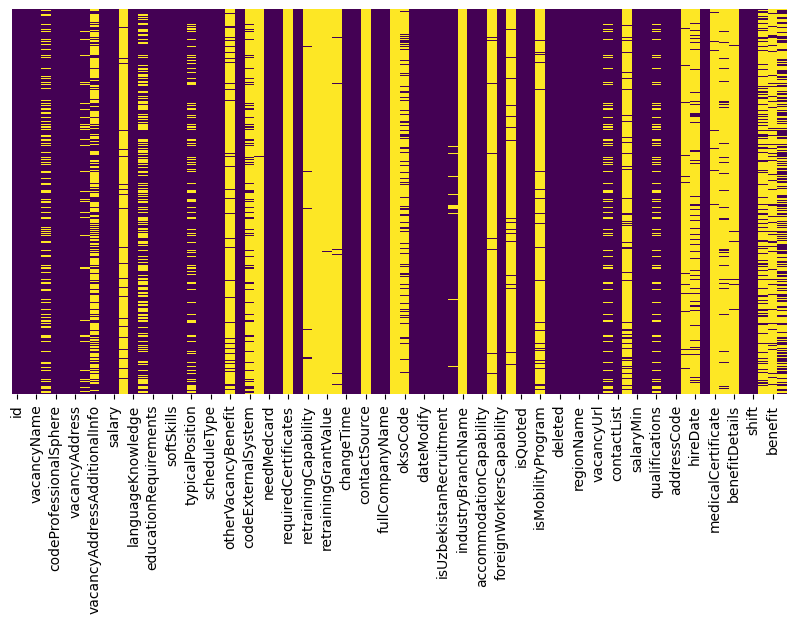

In [12]:
plt.figure(figsize=(10,5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap='viridis')
plt.show()

На графике показана тепловая карта пропусков (missing values heatmap).

🟣 Фиолетовый — значение присутствует

🟡 Жёлтый — значение отсутствует (NaN)

По нему можно понять какие поля и насколько регулярно заполняются.

Датасет имеет выраженную неравномерность заполнения значений признаков. Базовые и идентификационные поля (название вакансии, компания, регион, коды и идентификаторы) почти полностью заполнены. Содержательные характеристики (заработная плата, навыки, требования к образованию и опыту, условия труда и льготы) заполнены неполностью. Отдельные  признаки (медицинские справки, мобильные программы, возможности переобучения и проживания) содержат критически большое количество пропусков. 

💡 **Вывод:** Необходима дальнейшая предобработка данных: отбор информативных признаков, импутация пропусков и пр.

# 1. Описательные статистики <a class="anchor" id="chapter1"></a>

In [13]:
# разделим на группы числовые и категориальные признаки
numeric_features = df.select_dtypes(include=[np.number])
categorical_features = df.select_dtypes(exclude=[np.number])

In [14]:
numeric_features.describe()  # описательная статистика для числовых признаков

,stateRegionCode,codeProfession,retrainingСondition,retrainingGrantValue
count,5.114680e+05,393948.000000,0.0,1587.000000
mean,4.864004e+12,153415.024105,NaN,31253.805923
std,2.392222e+12,49445.900154,NaN,24167.367352
min,1.000000e+11,100001.000000,NaN,0.000000
25%,2.700000e+12,103804.000000,NaN,18900.000000
50%,5.000000e+12,200024.000000,NaN,30000.000000
75%,6.700000e+12,202045.000000,NaN,45000.000000
max,9.900000e+12,428052.000000,NaN,450000.000000


💡 **Вывод:** Очень странный результат. Почему нет зарплаты?

In [15]:
categorical_features.describe(include='object')  # описательная статистика для категориальных признаков

,id,vacancyName,codeProfessionalSphere,professionalSphereName,vacancyAddress,vacancyAddressHouse,vacancyAddressAdditionalInfo,geo,salary,socialProtecteds,...,hireDate,workPlace,medicalCertificate,scheduleTypeComment,benefitDetails,trainingDays,shift,medicalDocument,benefit,conditions
count,511468,511468,511426,511426,511199,473849,186797,511468,511464,37739,...,59456,511460,12159,31614,7900,511462.0,511460,118522,75376,246165
unique,511468,99226,35,35,186319,31402,106079,146069,23682,307,...,2390,1400,2791,2751,3025,108.0,10,3,370,4
top,d301be38-6f11-11f1-90b8-c7c4ad68b305,Продавец-кассир,Medicine,Здравоохранение и социальное обеспечение,Город Москва,1,г Москва,{},от 27093,Инвалид,...,2026-09-01T03:00:00+0300,"{""workPlaceForeign"": false, ""workPlaceOrdinary...",001-ГС/у,Без уточнения,премия,0.0,[],Медицинская книжка,Добровольное медицинское страхование,Допустимые
freq,1,13603,86678,86678,1882,21592,264,25546,42327,19618,...,8057,449360,325,19256,200,467829.0,438689,106363,16968,128078


💡 **Вывод:** Почему-то salary категориальный признак, надо разобраться.

In [16]:
df.salary.describe()

count       511464
unique       23682
top       от 27093
freq         42327
Name: salary, dtype: object

In [17]:
(df['salary']).dtype

dtype('O')

У признака строковый тип данных.

In [18]:
df['salary'].sample(20)

419419     от 38000
274396     от 60000
393174     от 40000
66885      от 27500
326855    от 127000
148748     от 76832
148137     от 54000
254637     от 39000
405461     от 39400
284040     от 33000
187788     от 67733
95402      от 30000
110843     от 86530
169681     от 40000
17292      от 50912
407090     от 27093
382811     от 50000
282258     от 27093
356636     от 40000
18928      от 27093
Name: salary, dtype: object

Удалим из значений текст 'от ' и заменим тип на целочисленный.

In [19]:
df['salary'] = (
    df['salary']
    .str.replace('от ', '')
)

df = df.dropna(subset=['salary'])
df['salary'] = df['salary'].astype(int)

In [20]:
df['salary'].dtype

dtype('int64')

Теперь целое число

In [22]:
df['salary'].describe()

count    511464.000000
mean      53240.117355
std       31489.926068
min           0.000000
25%       32715.000000
50%       45000.000000
75%       62500.000000
max      999999.000000
Name: salary, dtype: float64

In [23]:
df[df['salary'] > 100000].describe() 
# описательная статистика для выборки с зарплатой > 100000

,stateRegionCode,codeProfession,salary,retrainingСondition,retrainingGrantValue
count,2.784200e+04,17470.000000,27842.000000,0.0,58.000000
mean,5.370871e+12,159528.693417,149101.316285,NaN,55376.258621
std,2.381055e+12,48871.602454,47579.200045,NaN,40883.844939
min,1.000000e+11,100001.000000,100001.000000,NaN,0.000000
25%,3.600000e+12,103838.000000,116000.000000,NaN,31250.000000
50%,5.100000e+12,200380.000000,132000.000000,NaN,47650.000000
75%,7.700000e+12,201916.000000,170000.000000,NaN,72000.000000
max,9.500000e+12,204338.000000,999999.000000,NaN,250000.000000


Выведем отдельные статистики по зарплате

In [24]:
df.salary.mean().item()  # среднее

53240.117355278184

In [25]:
df.salary.min()  # минимум

0

In [26]:
df.salary.max()  # максимум

999999

In [27]:
df.salary.mode()  # мода

0    27093
Name: salary, dtype: int64

In [28]:
df.salary.median()  # медиана

45000.0

In [29]:
df.salary.quantile(0.5)  # медиана / 50-й перцентиль / 2-й квартиль

np.float64(45000.0)

In [30]:
df.salary.var()  # дисперсия

991615443.7866259

In [31]:
df.salary.std()  # стандартное отклонение

31489.926068294062

In [32]:
df.salary.quantile(0.1).item()  # 10-й перцентиль / 1-й дециль

27100.0

In [33]:
df.salary.quantile(0.25).item()  # 25-й перцентиль / 1-й квартиль

32715.0

In [34]:
df.salary.quantile(0.75).item()  # 75-й перцентиль / 3-й квартиль

62500.0

In [35]:
df.salary.quantile(0.9).item()  # 90-й перцентиль, 9-й дециль

85000.0

In [36]:
df.salary.quantile(0.75).item() - df.salary.quantile(0.25).item()  # межквартильный размах

29785.0

In [37]:
(df.salary.quantile(0.75).item() - df.salary.quantile(0.25).item())/2  # межквартильная широта

14892.5

In [38]:
df.salary.quantile(0.9).item()/df.salary.quantile(0.1).item()  # децильное отношение

3.1365313653136533

In [39]:
df[df.salary > 100000]['salary'].mean().item()
# средняя зп для вакансий с зп выше 100000

149101.31628474966

💡 **Вывод:** Медиана значительно отличается от среднего, стандартное отклонение высокое - большой разброс значений и ненормальное распределение. Значение минимальной зарплаты на уровне 90-го перцентиля примерно в 3,1 раза выше, чем на уровне 10-го перцентиля. 

# 2. Сводные таблицы и группировки <a class="anchor" id="chapter2"></a>

Метод `groupby()` позволяет группировать результаты расчётов по одному или нескольким признакам.

In [40]:
df.groupby('busyType')[['salary']].mean()  # средняя зп для разных типов занятости

,salary
busyType,
Временная работа,50248.577472
Дистанционная (удаленная) работа,58641.763380
Полная занятость,51039.097937
Сезонная работа,54709.433847
Стажировка,41643.914913
Частичная занятость,36925.696826


In [41]:
df.busyType.value_counts()

busyType
Полная занятость                    257675
Временная работа                     16761
Частичная занятость                   3371
Сезонная работа                       2789
Стажировка                            1093
Дистанционная (удаленная) работа       710
Name: count, dtype: int64

In [42]:
df.groupby('busyType')[['salary']].agg(['mean', 'std'])  # добавим в вывод стандартное отклонение

salary              
                                          mean           std
busyType                                                    
Временная работа                  50248.577472  36795.486734
Дистанционная (удаленная) работа  58641.763380  46939.182232
Полная занятость                  51039.097937  29768.324331
Сезонная работа                   54709.433847  36179.597902
Стажировка                        41643.914913  18026.992648
Частичная занятость               36925.696826  31564.971945

💡 **Вывод:** Средний уровень  зарплаты заметно варьируется в зависимости от типа занятости: наибольшие значения характерны для удалённой и сезонной работы, при этом  в этих группах наблюдается и высокий разброс, что указывает на неоднородность условий. Полная и временная занятость демонстрируют близкие средние значения, отражая более стабильный сегмент рынка. Наиболее низкие значения при частичной занятости и стажировках, что ожидаемо с учётом формата занятости и меньшего объёма рабочего времени.

Метод `pivot_table()` позволяет создавать сводные таблицы. Ему передаются три параметра:

- переменная по которой считается статистика (по умолчанию среднее арифметическое),
- переменная для группировки значений среднего по строкам (index),
- переменная для группировки значений среднего по столбцам (columns).

In [43]:
df.pivot_table('salary', index='busyType', columns='scheduleType') 
# средняя зп, сгруппированная по типу занятости и графику работы

scheduleType,Вахтовый метод,Ненормированный рабочий день,Неполный рабочий день/неполная рабочая неделя,Полный рабочий день,Режим гибкого рабочего времени,Сменная работа
busyType,,,,,,
Временная работа,121432.392050,58794.022901,29652.393677,52926.201872,44524.392857,46259.439776
Дистанционная (удаленная) работа,NaN,44665.714286,38911.314815,64988.914563,44420.257143,37529.758621
Полная занятость,127460.159015,66546.590172,33678.697952,49921.923464,45205.195456,51469.714270
Сезонная работа,110926.343023,72342.461538,34821.701923,53163.939050,53067.397727,45757.292767
Стажировка,87000.000000,43014.068182,34419.045455,41333.222222,38583.281250,45453.431138
Частичная занятость,NaN,32705.821429,30479.093416,42301.843023,43979.081340,98282.898936


In [44]:
df.pivot_table('salary', index='busyType', columns='scheduleType', aggfunc='max') 
# максимальная зп, сгруппированная по типу занятости и графику работы

scheduleType,Вахтовый метод,Ненормированный рабочий день,Неполный рабочий день/неполная рабочая неделя,Полный рабочий день,Режим гибкого рабочего времени,Сменная работа
busyType,,,,,,
Временная работа,350000.0,300000.0,275000.0,400000.0,148700.0,220000.0
Дистанционная (удаленная) работа,NaN,100000.0,229900.0,500000.0,110000.0,60000.0
Полная занятость,800000.0,999999.0,280000.0,999999.0,300000.0,450000.0
Сезонная работа,360000.0,240000.0,330000.0,350000.0,261000.0,210000.0
Стажировка,245000.0,80000.0,80000.0,150000.0,100000.0,100000.0
Частичная занятость,NaN,57896.0,200000.0,164275.0,120000.0,250000.0


In [45]:
df.pivot_table('salary', index='busyType', columns=['scheduleType', 'status'], 
               aggfunc=['mean', 'median'])
# вывод не только среднего, но и медианы

mean                 \
scheduleType                     Вахтовый метод                  
status                              Не одобрено       Одобрено   
busyType                                                         
Временная работа                            NaN  121432.392050   
Дистанционная (удаленная) работа            NaN            NaN   
Полная занятость                  161633.333333  127451.132802   
Сезонная работа                             NaN  110926.343023   
Стажировка                                  NaN   87000.000000   
Частичная занятость                         NaN            NaN   

                                                        \
scheduleType                                             
status                           Ожидает подтверждения   
busyType                                                 
Временная работа                                   NaN   
Дистанционная (удаленная) работа                   NaN   
Полная занятость                              105000.0   
Сезонная работа                                    NaN   
Стажировка                                         NaN   
Частичная занятость                                NaN   

                                                               \
scheduleType                     Ненормированный рабочий день   
status                                               Одобрено   
busyType                                                        
Временная работа                                 58794.022901   
Дистанционная (удаленная) работа                 44665.714286   
Полная занятость                                 66546.590172   
Сезонная работа                                  72342.461538   
Стажировка                                       43014.068182   
Частичная занятость                              32705.821429   

                                                                                \
scheduleType                     Неполный рабочий день/неполная рабочая неделя   
status                                                             Не одобрено   
busyType                                                                         
Временная работа                                                       35500.0   
Дистанционная (удаленная) работа                                           NaN   
Полная занятость                                                       30000.0   
Сезонная работа                                                            NaN   
Стажировка                                                                 NaN   
Частичная занятость                                                        NaN   

                                                                    \
scheduleType                                   Полный рабочий день   
status                                Одобрено         Не одобрено   
busyType                                                             
Временная работа                  29651.293055                 NaN   
Дистанционная (удаленная) работа  38911.314815       200000.000000   
Полная занятость                  33679.051741        59217.512821   
Сезонная работа                   34821.701923                 NaN   
Стажировка                        34419.045455                 NaN   
Частичная занятость               30479.093416                 NaN   

                                                                \
scheduleType                                                     
status                           Не опубликовано      Одобрено   
busyType                                                         
Временная работа                             NaN  52925.045578   
Дистанционная (удаленная) работа             NaN  64726.247082   
Полная занятость                         62781.0  49919.387584   
Сезонная работа                              NaN  53163.939050   
Стажировка                                   NaN  41333.222222   
Частичная занятость               

Слишком детальные таблицы, могу привести к большому числу пропусков. Этого лучше избегать.

💡 **Вывод:** Уровень  зарплаты существенно зависит от сочетания типа занятости, графика работы и статуса вакансии: наиболее высокие средние и медианные значения характерны для вакансий с полным рабочим днём и вахтовым методом, особенно при полной, сезонной и удалённой занятости. Вакансии со сменным, гибким или неполным графиком в среднем предлагают более низкие значения зарплаты, причём медианы часто заметно ниже средних, что указывает на наличие высоких единичных значений и асимметрию распределений. Большое количество пропусков ограничивает сопоставимость отдельных комбинаций.

# 3. Частотный анализ данных <a class="anchor" id="chapter3"></a>

Рассмотрим тип источника вакансии.

In [46]:
df['sourceType'].value_counts().to_frame() 
# частотная таблица, по умолчанию отсортирована в порядке убывания частоты

,count
sourceType,
Вакансия работодателя,432800
Вакансия интернет ресурса,76676
Вакансия кадрового агентства,1721
Цифровой хаб,206
Аккредитованное частное агентство занятости,61


In [47]:
df['sourceType'].value_counts(ascending=True).to_frame() 
# по возрастанию частоты

,count
sourceType,
Аккредитованное частное агентство занятости,61
Цифровой хаб,206
Вакансия кадрового агентства,1721
Вакансия интернет ресурса,76676
Вакансия работодателя,432800


In [48]:
df['sourceType'].value_counts(ascending=True).sort_index().to_frame() 
# по возрастанию значений (по алфавиту)

,count
sourceType,
Аккредитованное частное агентство занятости,61
Вакансия интернет ресурса,76676
Вакансия кадрового агентства,1721
Вакансия работодателя,432800
Цифровой хаб,206


Рассмотрим тип предоставляемого работодателем жилья.

In [49]:
df['accommodationType'].value_counts(dropna=False).sort_index().to_frame() 
# пропущенные значения не игнорируются

,count
accommodationType,
DORMITORY,6533
FLAT,3633
HOUSE,311
ROOM,655
NaN,500332


In [50]:
df['accommodationType'].nunique()  # число уникальных значений признака

4

In [51]:
df.groupby('accommodationType')['scheduleType'].value_counts().to_frame()  # частотная таблица с группировкой

count
accommodationType scheduleType                                        
DORMITORY         Полный рабочий день                             3981
                  Вахтовый метод                                  1452
                  Сменная работа                                   897
                  Ненормированный рабочий день                     132
                  Режим гибкого рабочего времени                    36
                  Неполный рабочий день/неполная рабочая неделя     35
FLAT              Полный рабочий день                             2907
                  Сменная работа                                   438
                  Неполный рабочий день/неполная рабочая неделя    110
                  Ненормированный рабочий день                      87
                  Вахтовый метод                                    53
                  Режим гибкого рабочего времени                    38
HOUSE             Полный рабочий день                              232
                  Сменная работа                                    37
                  Вахтовый метод                                    12
                  Ненормированный рабочий день                      11
                  Режим гибкого рабочего времени                    10
                  Неполный рабочий день/неполная рабочая неделя      9
ROOM              Полный рабочий день                              489
                  Сменная работа                                   105
                  Неполный рабочий день/неполная рабочая неделя     26
                  Режим гибкого рабочего времени                    15
                  Вахтовый метод                                    11
                  Ненормированный рабочий день                       9

💡 **Вывод:** Во всех категориях жилья доминирует полный рабочий день, особенно при размещении в общежитии и квартире, что указывает на ориентацию таких предложений на стабильную занятость. Вахтовый метод чаще всего сочетается с проживанием в общежитии, что логично с точки зрения организации труда и размещения работников, тогда как при проживании в квартире или комнате он встречается существенно реже. Сменная работа занимает второе место почти во всех типах жилья, а гибкий и неполный графики представлены минимально, что говорит о слабой связке альтернативных режимов труда с предоставлением проживания.

In [52]:
df['sourceType'].value_counts(normalize=True).to_frame()  # проценты вместо частот

,proportion
sourceType,
Вакансия работодателя,0.846198
Вакансия интернет ресурса,0.149915
Вакансия кадрового агентства,0.003365
Цифровой хаб,0.000403
Аккредитованное частное агентство занятости,0.000119


Выведем названия профессональных сфер.

In [53]:
df['professionalSphereName'].unique()  # уникальные значения в столбце

array(['Работы, не требующие квалификации',
       'Здравоохранение и социальное обеспечение',
       'Продажи, закупки, снабжение, торговля', 'Электроэнергетика',
       'Лесная, деревообрабатывающая, целлюлозно-бумажная промышленность',
       'Образование, наука',
       'Транспорт, автобизнес, логистика, склад, ВЭД', 'Производство',
       'Бухгалтерия, налоги, управленческий учет', 'Машиностроение',
       'Рабочие специальности', 'Пищевая промышленность',
       'Информационные технологии, телекоммуникации, связь',
       'Строительство, ремонт, стройматериалы, недвижимость',
       'Добывающая промышленность',
       'Сельское хозяйство, экология, ветеринария', 'ЖКХ, эксплуатация',
       'Искусство, культура и развлечения', 'Безопасность, службы охраны',
       'Туризм, гостиницы, рестораны', 'Легкая промышленность',
       'Услуги населению, сервисное обслуживание',
       'Административная работа, секретариат, АХО',
       'Химическая, нефтехимическая, топливная промышленност

Посмотрим сколько уникальных вакансий

In [54]:
df.vacancyName.nunique()

99226

Выведем самые часто встречающиеся наименования вакансий. 

In [55]:
top_10 = df['vacancyName'].value_counts().head(10)
print(top_10)

vacancyName
Продавец-кассир                                                13603
Продавец                                                        9664
Уборщик производственных и служебных помещений                  7493
Водитель автомобиля                                             6154
Повар                                                           6102
Администратор магазина                                          5495
Пекарь                                                          5436
Подсобный рабочий                                               5239
Дворник                                                         4569
Электромонтер по ремонту и обслуживанию электрооборудования     3999
Name: count, dtype: int64


Выведем все вакансии по профессии программист.

In [56]:
count = (df['vacancyName'].str.lower() == 'программист').sum()
print(f"Количество записей с точным наименованием вакансии 'программист': {count}")

Количество записей с точным наименованием вакансии 'программист': 575


In [57]:
count = df['vacancyName'].str.contains('программист', case=False, na=False).sum()
print(f"Количество записей содержащих в наименовании вакансии 'программист': {count}")

Количество записей содержащих в наименовании вакансии 'программист': 1915


# 4. Графический анализ данных <a class="anchor" id="chapter4"></a>

Построим облако слов по наименованиям вакансий.

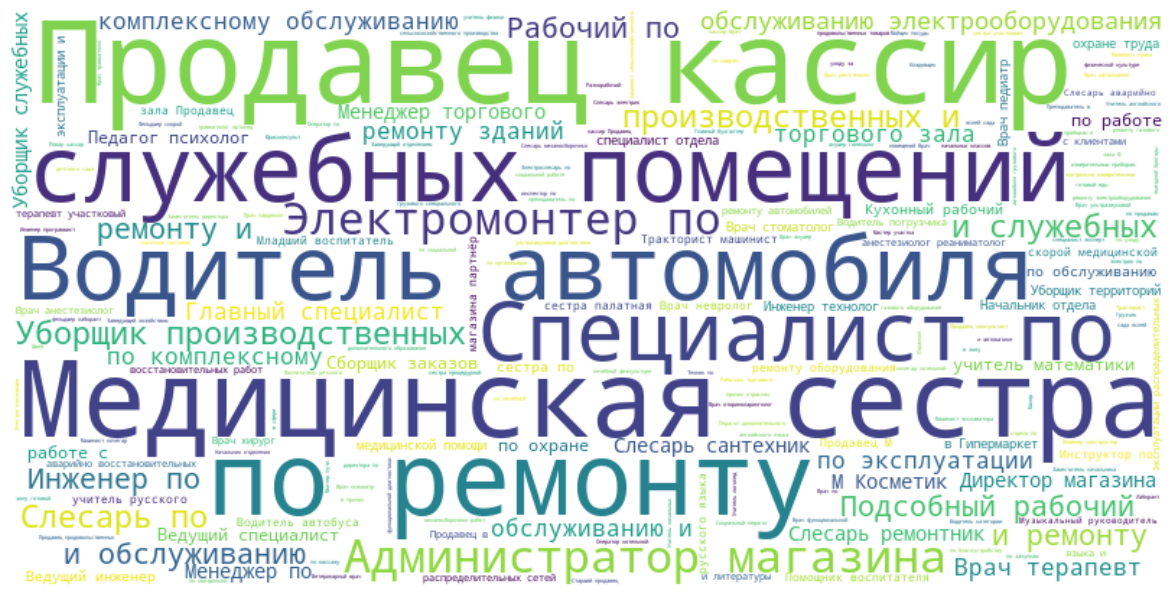

In [58]:
text = " ".join(df['vacancyName'].dropna().astype(str))
wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=200).generate(text)
plt.figure(figsize=(15, 7.5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

Посмотрим какие профессиональные сферы чаще встречаются.

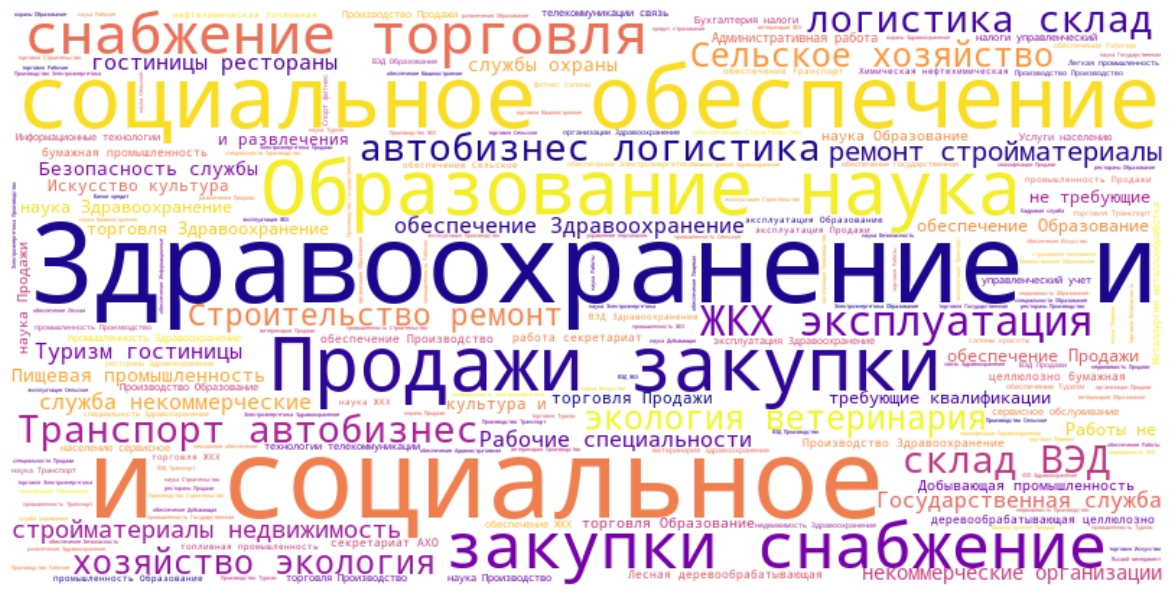

In [59]:
text = " ".join(df['professionalSphereName'].dropna().astype(str))
wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=200, colormap='plasma').generate(text)
plt.figure(figsize=(15, 7.5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

Визуализируем распределение зарплат меньше 100 тыс.

При построении гистограммы множество значений признака разбивается на k интервалов, эти интервалы становятся основаниями столбцов. Высота столбца пропорциональна количеству (частоте) значений признака, попадающих в соответствующий интервал.

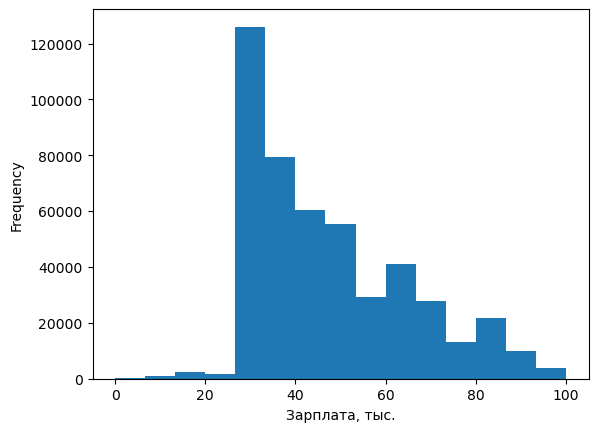

In [60]:
(df.loc[(df['salary'] != 0) & (df['salary'] < 100_000), 'salary'] / 1000).plot.hist(bins=15)
# параметр bins определяет число столбиков
plt.xlabel('Зарплата, тыс.');

В выборке есть экстремально высокие зарплаты.

In [61]:
count = (df['salary'] == 999999.000000).sum()
print(count)

4


In [62]:
top_n = df.sort_values(by='salary', ascending=False).head(30)
print(top_n[['vacancyName', 'salary']])

                                              vacancyName  salary
234285                        Военнослужащий по контракту  999999
452239                                     Военнослужащий  999999
245282                        Военнослужащий по контракту  999999
215961                        Военнослужащий по контракту  999999
132964                                            Плотник  900000
95830                                    Электромонтажник  900000
334557                                            Капитан  800000
51623                                    Приемщик заказов  730800
40664                                    Приемщик заказов  661500
357086               Электромеханик по судовой автоматике  600000
311321                       Директор по развитию бизнеса  580000
384642                           Директор по производству  550000
56353                          Машинист крана гусеничного  530000
53941                          Машинист буровой установки  530000
120680    

Посмотрим на вакансии, в названиях которых встречается 'программист'.

In [63]:
it_vacancies = df[df['vacancyName'].str.contains('программист', case=False, na=False)]['vacancyName']
print(it_vacancies)

203                                     Инженер-программист
406                                             Программист
431                                             Программист
954                                     инженер-программист
1241                                         Программист 1С
1500                                            Программист
2125                                    Инженер-программист
2215                                    Инженер-программист
2275                                         Программист 1С
2483                                         Программист 1С
2506                                     Техник-программист
2854                            старший инженер-программист
3055                                    Инженер-программист
3110                                    Инженер-программист
3117                                    Инженер-программист
3349                                    Инженер-программист
3921                        Инженер - си

💡 **Вывод:** Видим разные варианты написания похожих должностей. Это все нужно будет унифицировать. 

Рассмотрим зарплаты по вакансиям, в которых в наименовании есть слово 'программист'.

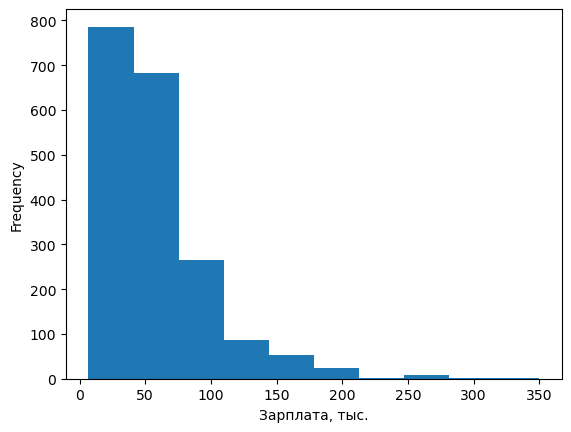

In [64]:
(
    df.loc[
        (df['salary'] != 0) &
        (df['vacancyName'].str.contains('программист', case=False, na=False)),'salary'
    ] / 1000
).plot.hist(bins=10)

plt.xlabel('Зарплата, тыс.');

Для категориальных признаков лучше строить столбчатую или круговую диаграмму.

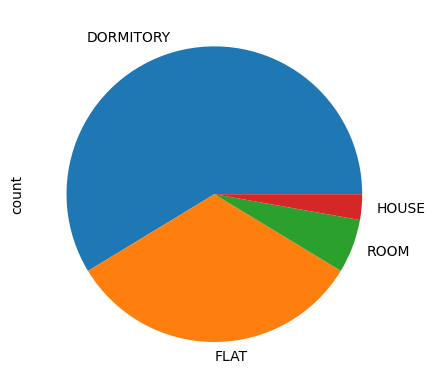

In [65]:
df.accommodationType.value_counts().plot(kind='pie');

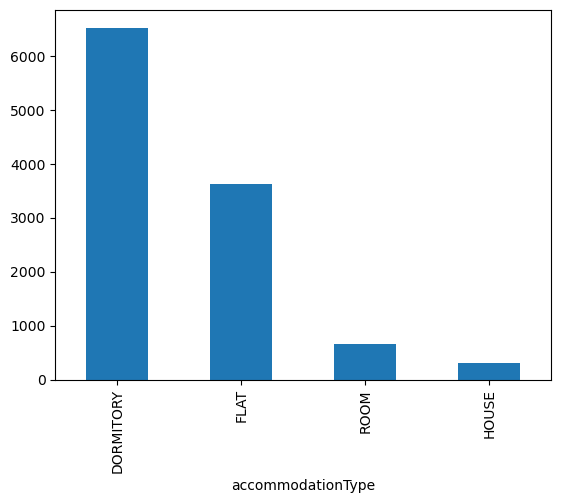

In [66]:
df.accommodationType.value_counts().plot(kind='bar');

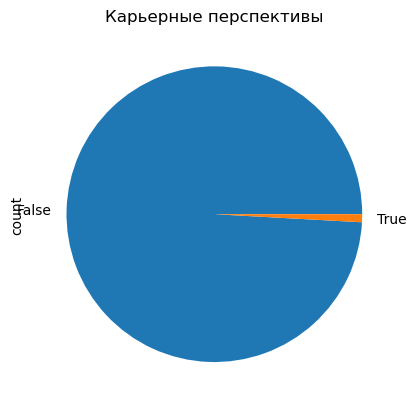

In [67]:
df.careerPerspective.value_counts().plot(kind='pie', title = 'Карьерные перспективы');  # у графика есть название

Диаграмма рассеяния (scatter plot) — это график, на котором каждая точка отображает пару значений из двух признаков.

Ось X → значения одного признака.

Ось Y → значения второго признака.

Каждая точка на графике соответствует одной наблюдаемой паре (x, y).

Может использоваться для следующих целей:

- увидеть зависимость между признаками (линейная, нелинейная, отсутствие взаимосвязи);

- для поиска кластеров или выбросов в данных;

- для проверки гипотез о корреляции.

Визуализируем взаимосвязь между salaryMin и salaryMax.

In [68]:
df['salaryMax'].describe()

count     511460.0
unique     28770.0
top        50000.0
freq       25328.0
Name: salaryMax, dtype: float64

Удалим из значений текст 'от ' и заменим тип на целочисленный.

In [71]:
df['salaryMax'] = (
    df['salaryMax']
    .str.replace('от ', '')
)

In [72]:
df['salaryMax'].describe()

count     40956
unique     4510
top       50000
freq       2070
Name: salaryMax, dtype: object

Тип все равно остался текстовым.

In [75]:
top_5 = sorted(df["salaryMax"].dropna().unique(), reverse=True)[:5]
print(top_5)

['Погрузка, разгрузка и перемещение готовой продукции и материалов вручную и с использованием механизмов. Участие в благоустройстве территорий: Выполнение других поручений руководства, не требующих специальной квалификации.', '999999', '99999', '99861', '99840']


Какой-то странный текст, удалим его.

Преобразуем столбец salaryMax в числовой формат. Если в нём встречаются значения, которые нельзя преобразовать в число, то они заменяются на NaN.

In [76]:
df["salaryMax"] = pd.to_numeric(df["salaryMax"], errors="coerce")

In [77]:
df = df.dropna(subset=['salaryMax'])

In [78]:
df['salaryMax'].describe()

count     40955.000000
mean      62645.273910
std       40079.217535
min           0.000000
25%       39000.000000
50%       54186.000000
75%       75000.000000
max      999999.000000
Name: salaryMax, dtype: float64

Проделаем то же самое с минимальной зарплатой.

In [79]:
df['salaryMin'].describe()

count     40955
unique     4863
top       27093
freq       2499
Name: salaryMin, dtype: int64

In [80]:
df['salaryMin'] = (
    df['salaryMin']
    .str.replace('от ', '')
)

In [83]:
df["salaryMin"] = pd.to_numeric(df["salaryMin"], errors="coerce")

In [84]:
df = df.dropna(subset=['salaryMin'])

In [85]:
df['salaryMin'].describe()

count      8191.000000
mean      52214.983152
std       31608.236858
min           0.000000
25%       31156.500000
50%       45000.000000
75%       60000.000000
max      350000.000000
Name: salaryMin, dtype: float64

Построим диаграмму рассеяния.

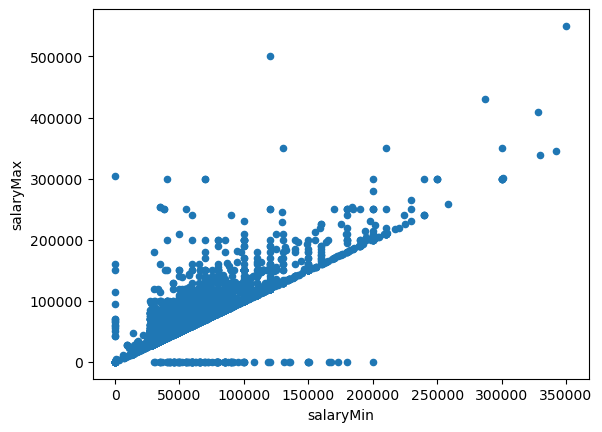

In [86]:
df.plot.scatter(x = 'salaryMin', y = 'salaryMax');

Выведем на графике зарплаты в тысячах рублей.

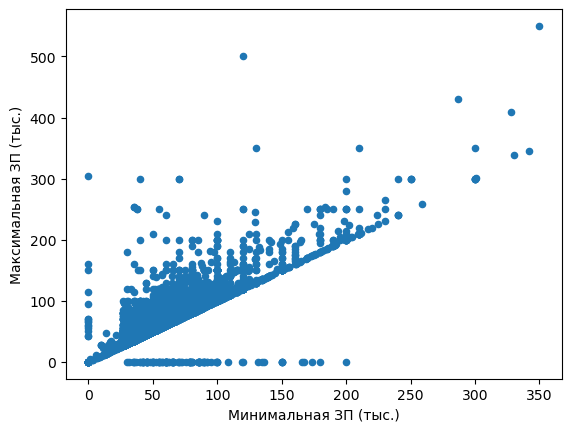

In [87]:
df["salaryMin_k"] = df["salaryMin"] / 1000
df["salaryMax_k"] = df["salaryMax"] / 1000

df.plot.scatter(x="salaryMin_k", y="salaryMax_k")
plt.xlabel("Минимальная ЗП (тыс.)")
plt.ylabel("Максимальная ЗП (тыс.)");

Ящичковая диаграмма — это способ отображения распределения данных на основе пяти числовых характеристик: минимум, первый квартиль (Q1), медиана, третий квартиль (Q3) и максимум. Она позволяет выявлять выбросы.

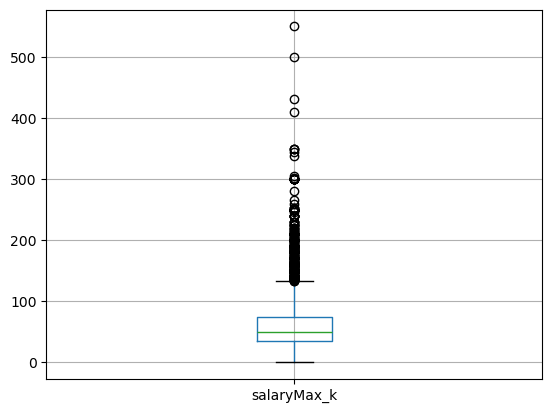

In [88]:
df.boxplot(column='salaryMax_k');

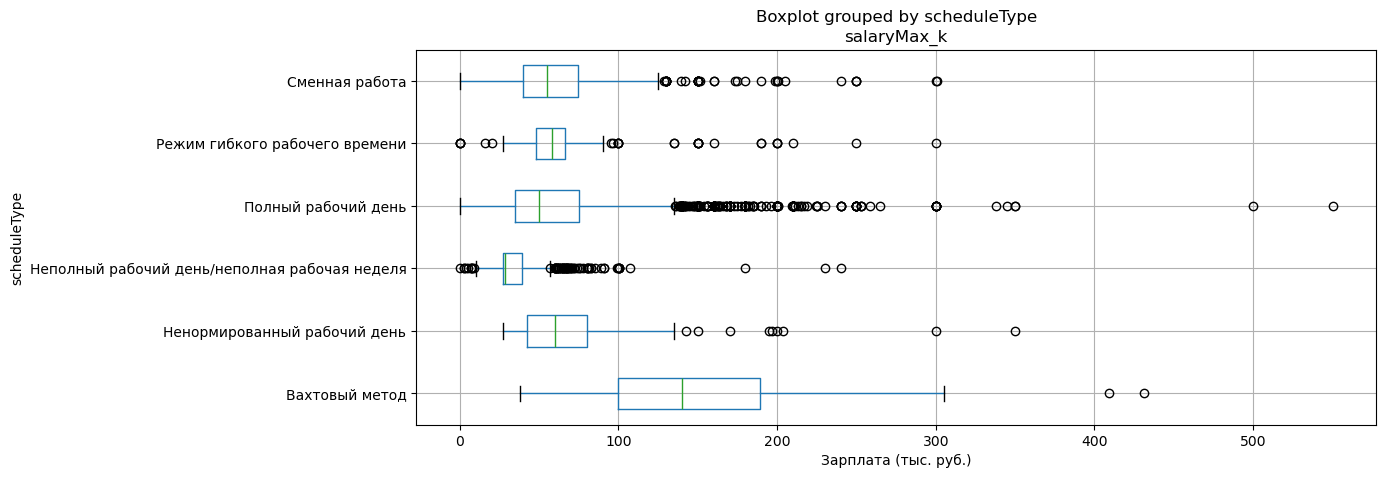

In [90]:
df.boxplot(column='salaryMax_k', by='scheduleType', figsize=(12, 5), vert=False);
plt.xlabel("Зарплата (тыс. руб.)");
# ящичковая диаграмма с группировкой

💡 **Вывод:** Наиболее высокая медианная зарплата наблюдается при вахтовом методе, который также отличается самым широким разбросом доходов, что может быть связано со сложными условиями труда. Полный рабочий день, ненормированный и сменный графики имеют близкие медианные значения, при этом у полного рабочего дня встречаются самые высокие отдельные зарплаты — до 500–550 тыс. руб. Гибкий график характеризуется умеренными зарплатами и меньшим разбросом, а неполный рабочий день/неделя имеет самую низкую медиану и в целом самый низкий уровень доходов, несмотря на отдельные высокие выбросы.

Сравним распределение зарплаты с нормальным.

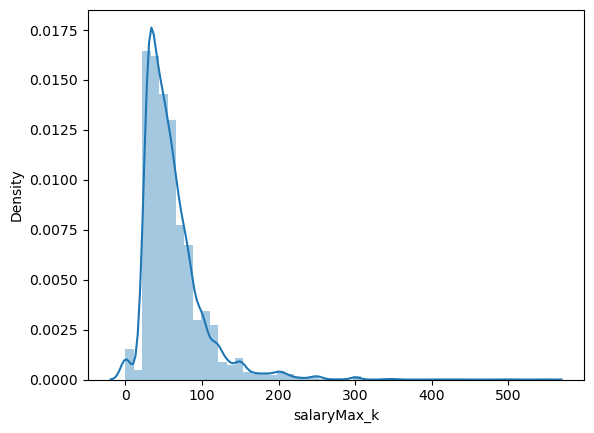

In [91]:
sns.distplot(df.salaryMax_k);  # график распределения значений

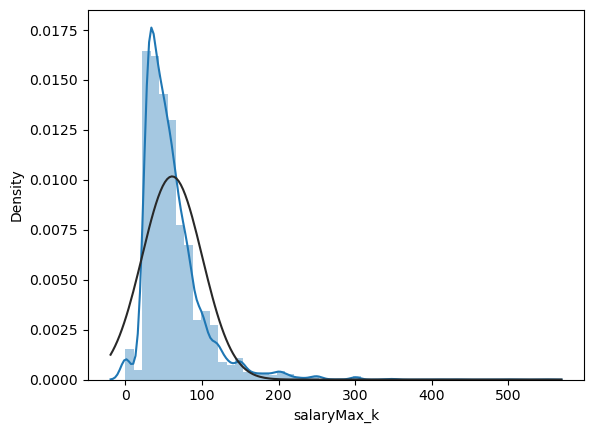

In [92]:
sns.distplot(df.salaryMax_k, fit=norm);  # добавляем график нормального распределения поверх существующего

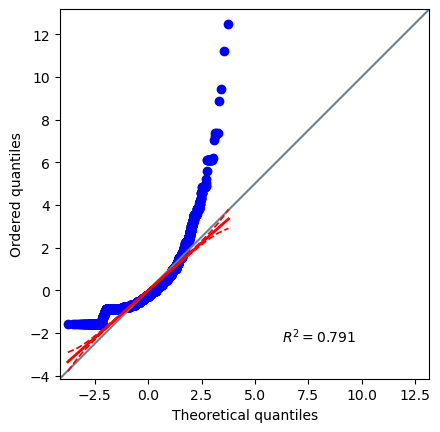

In [93]:
pg.qqplot(df.salaryMax_k, dist = 'norm');

In [96]:
df.salaryMax_k.skew().item()  # асимметрия

2.6701188662714355

Распределение имеет положительную асимметрию. В выборке превалируют низкие зарплаты.

In [98]:
df.salaryMax_k.kurtosis().item()  # эксцесс

13.61390192918681

💡 **Вывод:** Распределение пиковое, большинство значений сконцентрированы в довольно узком диапазоне.

Про графики в Python:
- https://python-graph-gallery.com/
- https://www.machinelearningplus.com/plots/top-50-matplotlib-visualizations-the-master-plots-python/

# 5. Таблицы сопряжённости<a class="anchor" id="chapter5"></a>

[Подробнее о построении таблиц сопряженности](https://pbpython.com/pandas-crosstab.html)

In [99]:
pd.crosstab(df['busyType'], df['scheduleType'])  # ячейки содержат частоты

scheduleType,Вахтовый метод,Ненормированный рабочий день,Неполный рабочий день/неполная рабочая неделя,Полный рабочий день,Режим гибкого рабочего времени,Сменная работа
busyType,,,,,,
Временная работа,11,3,176,128,7,19
Дистанционная (удаленная) работа,0,0,1,8,7,4
Полная занятость,89,91,172,3024,66,664
Сезонная работа,0,1,2,26,1,3
Стажировка,0,0,2,10,1,2
Частичная занятость,0,0,35,10,2,1


In [100]:
pd.crosstab(df['busyType'], df['scheduleType'], margins=True)  # добавлены суммы по строкам и столбцам

scheduleType,Вахтовый метод,Ненормированный рабочий день,Неполный рабочий день/неполная рабочая неделя,Полный рабочий день,Режим гибкого рабочего времени,Сменная работа,All
busyType,,,,,,,
Временная работа,11,3,176,128,7,19,344
Дистанционная (удаленная) работа,0,0,1,8,7,4,20
Полная занятость,89,91,172,3024,66,664,4106
Сезонная работа,0,1,2,26,1,3,33
Стажировка,0,0,2,10,1,2,15
Частичная занятость,0,0,35,10,2,1,48
All,100,95,388,3206,84,693,4566


In [101]:
pd.crosstab(df['busyType'], df['scheduleType'], margins=True, normalize=True) 
# проценты вместо частот

scheduleType,Вахтовый метод,Ненормированный рабочий день,Неполный рабочий день/неполная рабочая неделя,Полный рабочий день,Режим гибкого рабочего времени,Сменная работа,All
busyType,,,,,,,
Временная работа,0.002409,0.000657,0.038546,0.028033,0.001533,0.004161,0.075339
Дистанционная (удаленная) работа,0.000000,0.000000,0.000219,0.001752,0.001533,0.000876,0.004380
Полная занятость,0.019492,0.019930,0.037670,0.662286,0.014455,0.145423,0.899255
Сезонная работа,0.000000,0.000219,0.000438,0.005694,0.000219,0.000657,0.007227
Стажировка,0.000000,0.000000,0.000438,0.002190,0.000219,0.000438,0.003285
Частичная занятость,0.000000,0.000000,0.007665,0.002190,0.000438,0.000219,0.010512
All,0.021901,0.020806,0.084976,0.702146,0.018397,0.151774,1.000000


💡 **Вывод:** 66% вакансий предусматривают полную занятость на полный рабочий день. 15% - сменная работа на полную занятость.

In [102]:
pd.crosstab(df['busyType'], df['scheduleType'], margins=True, normalize='columns')
# сумма значений каждого столбца равна 1

scheduleType,Вахтовый метод,Ненормированный рабочий день,Неполный рабочий день/неполная рабочая неделя,Полный рабочий день,Режим гибкого рабочего времени,Сменная работа,All
busyType,,,,,,,
Временная работа,0.11,0.031579,0.453608,0.039925,0.083333,0.027417,0.075339
Дистанционная (удаленная) работа,0.00,0.000000,0.002577,0.002495,0.083333,0.005772,0.004380
Полная занятость,0.89,0.957895,0.443299,0.943231,0.785714,0.958153,0.899255
Сезонная работа,0.00,0.010526,0.005155,0.008110,0.011905,0.004329,0.007227
Стажировка,0.00,0.000000,0.005155,0.003119,0.011905,0.002886,0.003285
Частичная занятость,0.00,0.000000,0.090206,0.003119,0.023810,0.001443,0.010512


💡 **Вывод:** Практически во всех группах превалирует полная занятость, но меньше всего ее доля в группе "Неполный рабочий день".

In [103]:
pd.crosstab(df['busyType'], df['scheduleType'], margins=True, normalize='index')
# устанавливаем параметр normalize='index'
# получаем процент по строкам

scheduleType,Вахтовый метод,Ненормированный рабочий день,Неполный рабочий день/неполная рабочая неделя,Полный рабочий день,Режим гибкого рабочего времени,Сменная работа
busyType,,,,,,
Временная работа,0.031977,0.008721,0.511628,0.372093,0.020349,0.055233
Дистанционная (удаленная) работа,0.000000,0.000000,0.050000,0.400000,0.350000,0.200000
Полная занятость,0.021676,0.022163,0.041890,0.736483,0.016074,0.161715
Сезонная работа,0.000000,0.030303,0.060606,0.787879,0.030303,0.090909
Стажировка,0.000000,0.000000,0.133333,0.666667,0.066667,0.133333
Частичная занятость,0.000000,0.000000,0.729167,0.208333,0.041667,0.020833
All,0.021901,0.020806,0.084976,0.702146,0.018397,0.151774


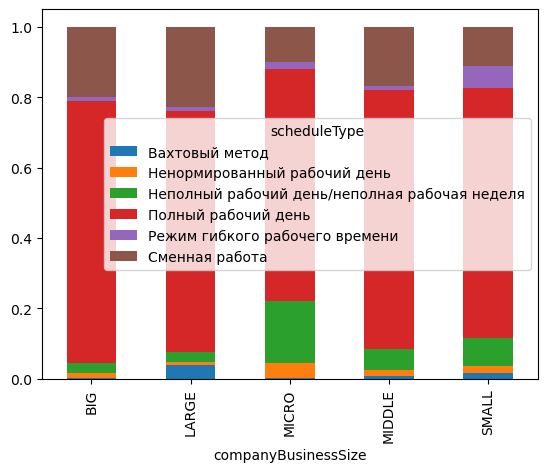

In [104]:
(
    df
    .groupby('companyBusinessSize')['scheduleType']
    .value_counts(normalize=True)
    .unstack()
    .plot(kind='bar', stacked=True)
);

Можно скомбинировать тепловую карту и таблицу сопряженности.

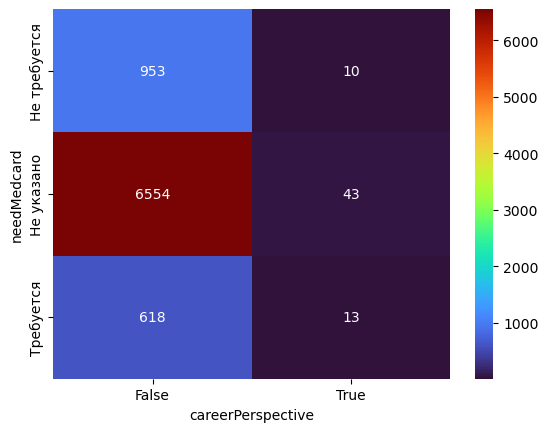

In [105]:
sns.heatmap(
    pd.crosstab(df['needMedcard'], df['careerPerspective']),
    annot=True,
    fmt='d',
    cmap='turbo'
);

# 6. Корреляционный анализ<a class="anchor" id="chapter6"></a>

Для демонстрации корреляционного анализа будем использовать другой датасет, потому в текущем кроме зарплаты нет числовых признаков, нет нормально распределенных признаков, а хотелось бы продемонстрировать все возможности корреляционного анализа данных.

Источник данных:  [Global Innovation Index](https://www.wipo.int/en/web/global-innovation-index)

Файл `WIPO-GII.xlsx` содержит панельные данные за 3 года (2020, 2021, 2022) про инновационное развитие стран.

Список переменных:
- Business environment
- Business sophistication index
- Citable documents H-index
- Creative goods and services
- Creative goods exports, % total trade
- Creative outputs index
- Cultural and creative services exports, % total trade
- Domestic market scale, bn PPP (U.S. dollars)
- Ease of getting credit
- Ease of starting a business
- Ecological sustainability
- Expenditure on education, % GDP
- Firms offering formal training, %
- General infrastructure
- Global Innovation Index
- Government effectiveness
- Government's online service
- Graduates in science and engineering, %
- Gross expenditure on R&D, % GDP
- High-tech exports, % total trade
- High-tech imports, % total trade
- High-tech manufacturing, %
- Human capital and research index
- Information and Communications Technology access
- Information and Communications Technology services exports, % total trade
- Information and Communications Technology services imports, % total trade
- Information and Communications Technology use
- Infrastructure index
- Intangible assets
- Joint venture/strategic alliance deals/bn PPP (U.S. dollars) GDP
- Knowledge absorption
- Knowledge and technology outputs index
- Knowledge workers
- Knowledge-intensive employment, %
- Logistics performance
- Market sophistication index
- Mobile app creation/bn PPP (U.S. dollars) GDP
- Online creativity
- PISA scales in reading, maths and science
- Political and operational stability
- Political environment
- Pupil-teacher ratio, secondary
- QS university ranking average score of top 3 universities
- Research and development (R&D)
- Scientific and technical articles/bn PPP (U.S. dollars) GDP
- Software spending, % GDP
- Tertiary education
- Tertiary enrolment, % gross
- University-industry R&D collaboration
- Region
- Euro area
- European Union
- OECD members
- Least developed countries
- Income

In [106]:
df2 = pd.read_excel('WIPO-GII.xlsx')
df2.head()

,Country,Business environment_2020,Business environment_2021,Business environment_2022,Business sophistication index_2020,Business sophistication index_2021,Business sophistication index_2022,Citable documents H-index_2020,Citable documents H-index_2021,Citable documents H-index_2022,...,University-industry R&D collaboration_2021,University-industry R&D collaboration_2022,Region,Region2,Euro area,European Union,OECD members,Least developed countries,Income,High income
0,Cote d'Ivoire,70.8,70.8,48.3,19.7,20.9,21.8,6.3,6.1,5.1,...,38.1,38.5,Sub-Saharan Africa,Sub-Saharan Africa,0,0,0,0,middle income,0
1,Czechia,81.1,81.1,42.1,46.2,43.5,46.2,29.8,30.3,30.4,...,53.7,59.1,Europe & Central Asia,Europe,0,1,1,0,high income,1
2,"Egypt, Arab Rep.",65.0,65.0,45.0,18.7,18.0,20.4,17.4,17.7,18.0,...,44.3,47.0,Middle East & North Africa,Middle East and North Africa,0,0,0,0,middle income,0
3,"Hong Kong SAR, China",81.9,81.9,69.7,45.4,45.2,46.7,36.5,37.3,38.4,...,61.3,62.9,East Asia & Pacific,Asia-Pacific,0,0,0,0,high income,1
4,"Iran, Islamic Rep.",51.4,51.4,13.3,17.9,16.5,18.6,19.7,20.5,22.1,...,26.7,27.7,Middle East & North Africa,Middle East and North Africa,0,0,0,0,middle income,0


In [107]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8191 entries, 73728 to 81919
Data columns (total 82 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   id                            8191 non-null   object 
 1   stateRegionCode               8191 non-null   int64  
 2   vacancyName                   8191 non-null   object 
 3   codeProfession                6528 non-null   float64
 4   codeProfessionalSphere        8189 non-null   object 
 5   professionalSphereName        8189 non-null   object 
 6   vacancyAddress                8188 non-null   object 
 7   vacancyAddressHouse           7833 non-null   object 
 8   vacancyAddressAdditionalInfo  2648 non-null   object 
 9   geo                           8191 non-null   object 
 10  salary                        8191 non-null   int64  
 11  socialProtecteds              538 non-null    object 
 12  languageKnowledge             8191 non-null   object 
 13  bus

Проверим на нормальность распределение нескольких признаков. Будем использовать тест на нормальность Колмогорова-Смирнова.

**1. Information and Communications Technology services exports, % total trade_2022**

In [113]:
data = df2['Information and Communications Technology services exports, % total trade_2022'].dropna()

result = stats.kstest(data, 'norm', args=(data.mean(), data.std()))

print(f"statistic={result.statistic}")
print(f"p-value={result.pvalue}")

statistic=0.18510494276698747
p-value=0.00019710582816674646


H0: Распределение значений признака "Экспорт услуг в сфере информационно-коммуникационных технологий, % от общего объема" не отличается от нормального.

H1: Распределение значений признака "Экспорт услуг в сфере информационно-коммуникационных технологий, % от общего объема" отличается от нормального.

Вывод: поскольку p-value < 0.05, отвергаем нулевую гипотезу => распределение признака статистически значимо отличается от нормального

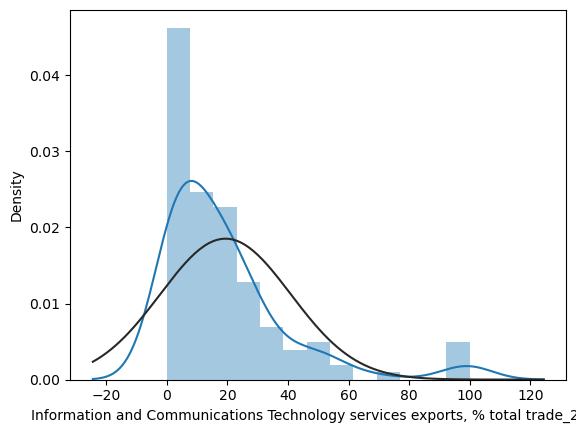

In [114]:
sns.distplot(df2['Information and Communications Technology services exports, % total trade_2022'].
             dropna(), fit=norm); 

В дополнение к построению графика распределения значений признака, мы можем использовать график квантиль-квантиль (Q-Q) для оценки отклонения исходных данных от теоретического (нормального, в данном случае) распределения.

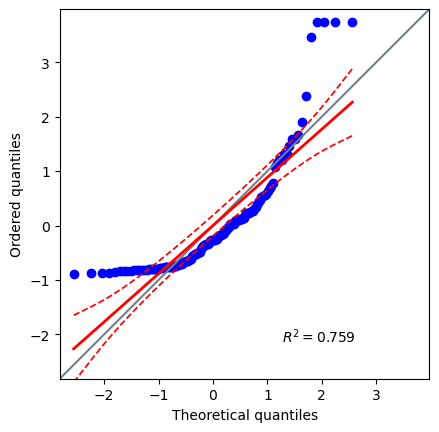

In [115]:
pg.qqplot(df2['Information and Communications Technology services exports, % total trade_2022'], dist = 'norm');

💡 **Вывод:** На графике видно, что квантили в наших данных заметно отличаются от квантилей нормального распределения. R^2 — это коэффициент детерминации, который измеряет качество соответствия линейной модели — красной линии — нашим данным и, следовательно, оценивает, насколько хорошо данное отношение может быть аппроксимировано линейной функцией. Чем лучше линейная модель соответствует данным, тем более похожи два распределения. В данном случае график показывает, что эмпирическое распределение далеко от нормального. Это дополнительно подтверждается гистограммой и статистическим тестом выше.

**2. University-industry R&D collaboration_2022**

In [119]:
data2 = df2['University-industry R&D collaboration_2022'].dropna()

result2 = stats.kstest(data2, 'norm', args=(data2.mean(), data2.std()))

print(f"statistic={result2.statistic}")
print(f"p-value={result2.pvalue}")

statistic=0.06285755871505036
p-value=0.6505715098926619


Поскольку p-value = 0.65 > 0.05, мы не отвергаем нулевую гипотезу (H0). Это означает, что у нас нет статистически значимых оснований полагать, что распределение значений признака отличается от нормального.

💡 **Вывод:** Распределение статистически не отличается от нормального.

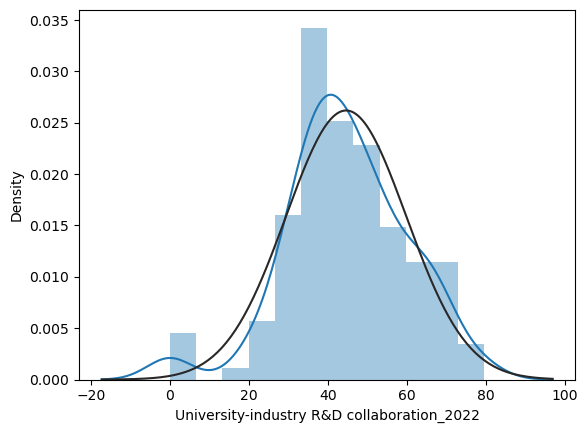

In [120]:
sns.distplot(df2['University-industry R&D collaboration_2022'].dropna(), fit=norm);

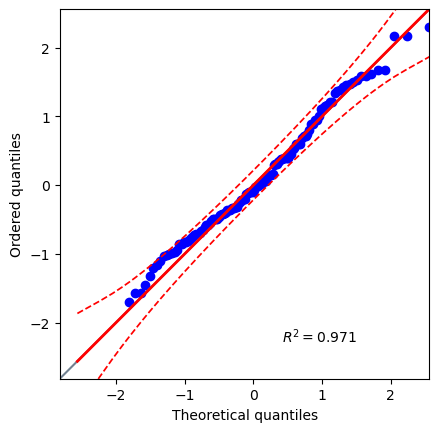

In [121]:
pg.qqplot(df2['University-industry R&D collaboration_2022'], dist = 'norm');

**3. Information and Communications Technology use_2022**

In [122]:
data3 = df2['Information and Communications Technology use_2022'].dropna()

result3 = stats.kstest(data3, 'norm', args=(data3.mean(), data3.std()))

print(f"statistic={result3.statistic}")
print(f"p-value={result3.pvalue}")

statistic=0.13715514990599909
p-value=0.012556473409898183


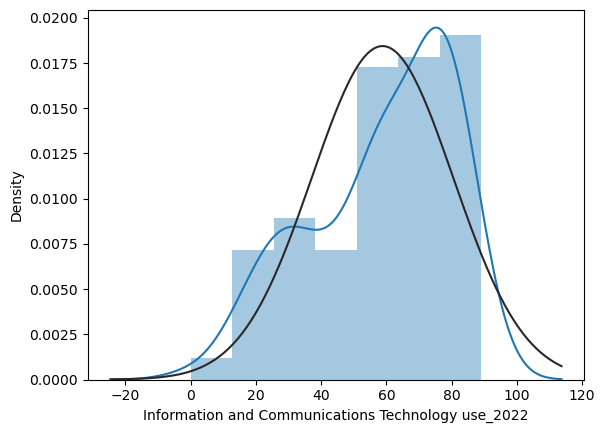

In [123]:
sns.distplot(df2['Information and Communications Technology use_2022'].dropna(), fit=norm);

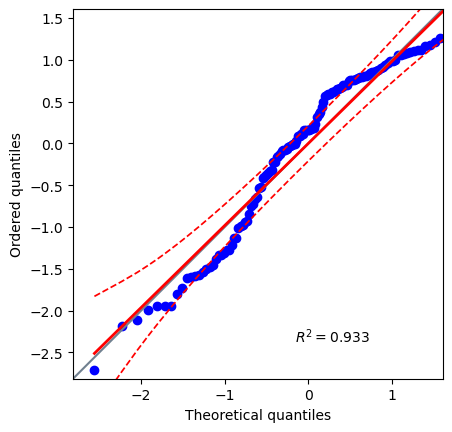

In [124]:
pg.qqplot(df2['Information and Communications Technology use_2022'], dist = 'norm');

💡 **Вывод:** Распределение отличается от нормального

**4. High-tech manufacturing, %_2022**

In [128]:
data4 = df2['High-tech manufacturing, %_2022'].dropna()

result4 = stats.kstest(data4, 'norm', args=(data4.mean(), data4.std()))

print(f"statistic={result4.statistic}")
print(f"p-value={result4.pvalue}")

statistic=0.1286546983117936
p-value=0.023016971341588865


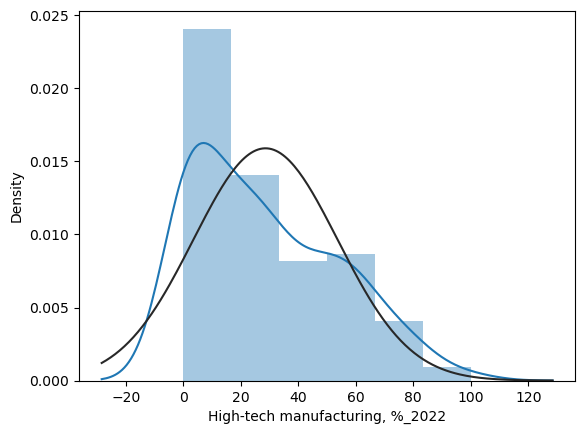

In [126]:
sns.distplot(df2['High-tech manufacturing, %_2022'].dropna(), fit=norm);

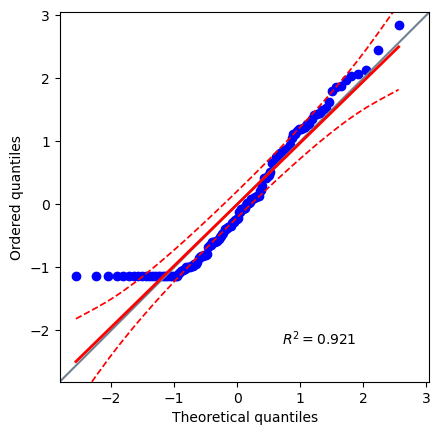

In [127]:
pg.qqplot(df2['High-tech manufacturing, %_2022'], dist = 'norm');

💡 **Вывод:** Распределение отличается от нормального

**5. Government effectiveness_2022**

In [129]:
data5 = df2['Government effectiveness_2022'].dropna()

result5 = stats.kstest(data5, 'norm', args=(data5.mean(), data5.std()))

print(f"statistic={result5.statistic}")
print(f"p-value={result5.pvalue}")

statistic=0.0793056239165289
p-value=0.3586404782482153


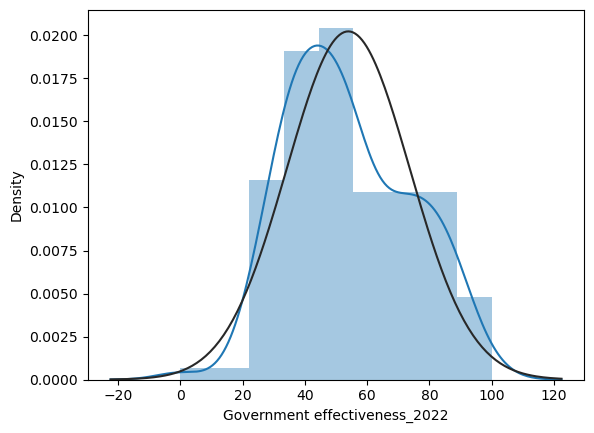

In [130]:
sns.distplot(df2['Government effectiveness_2022'].dropna(), fit=norm);

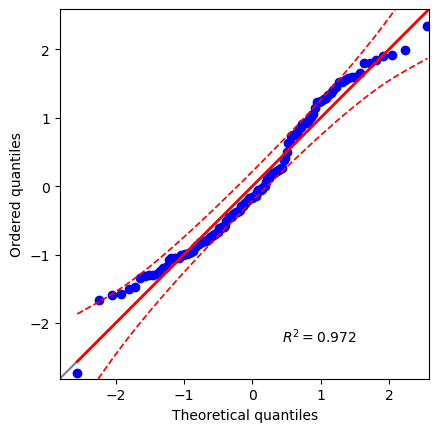

In [131]:
pg.qqplot(df2['Government effectiveness_2022'], dist = 'norm');

💡 **Вывод:** Распределение не отличается от нормального

**6. Business environment_2022**

In [132]:
data6 = df2['Business environment_2022'].dropna()

result6 = stats.kstest(data6, 'norm', args=(data6.mean(), data6.std()))

print(f"statistic={result6.statistic}")
print(f"p-value={result6.pvalue}")

statistic=0.042580660762039146
p-value=0.9621605872389752


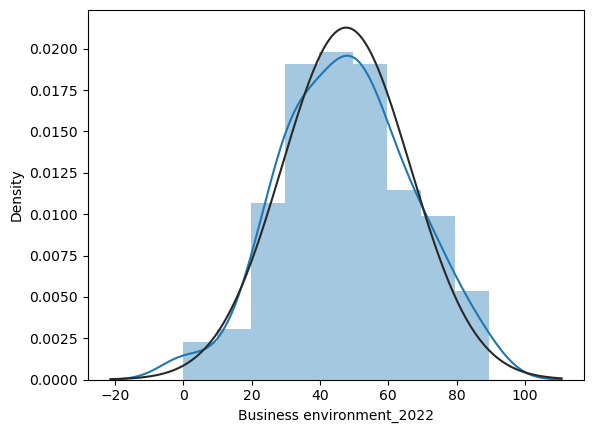

In [133]:
sns.distplot(df2['Business environment_2022'].dropna(), fit=norm);

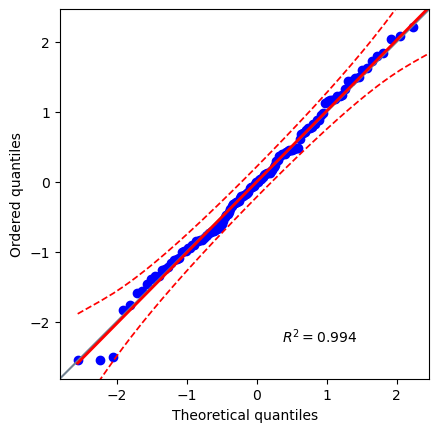

In [134]:
pg.qqplot(df2['Business environment_2022'], dist = 'norm');

💡 **Вывод:** Распределение не отличается от нормального

**7. Creative goods and services_2022**

In [135]:
data7 = df2['Creative goods and services_2022'].dropna()

result7 = stats.kstest(data7, 'norm', args=(data7.mean(), data7.std()))

print(f"statistic={result7.statistic}")
print(f"p-value={result7.pvalue}")

statistic=0.1059332353284872
p-value=0.09606350812447684


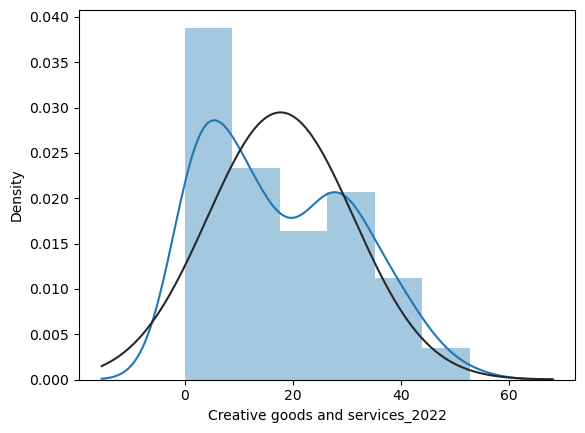

In [136]:
sns.distplot(df2['Creative goods and services_2022'].dropna(), fit=norm);

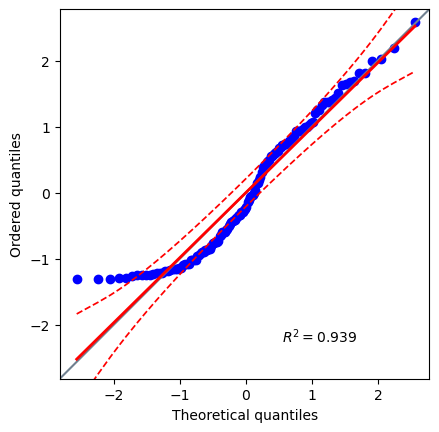

In [137]:
pg.qqplot(df2['Creative goods and services_2022'], dist = 'norm');

💡 **Вывод:** Распределение не отличается от нормального

💡 **Вывод:** Мы проанализировали распределение значений 7-ти признаков. Четыре из них имеют распределения, которые статистически значимо не отличаются от нормального, остальные три признака имеют распределения, которые статистически значимо отличаются от нормального.

### Коэффициент корреляции Пирсона

Ниже рассчитываются коэффициенты корреляции Пирсона между всеми возможными парами числовых признаков. Это не самое лучшее решение, потому что для расчета взаимосвязи между определенными парами признаков датасета этот коэффициент дает недостаточно точную оценку. 

По диагонали матрицы всегда 1, это корреляция признака с самой собой.

In [138]:
df2.corr(numeric_only=True) 

,Business environment_2020,Business environment_2021,Business environment_2022,Business sophistication index_2020,Business sophistication index_2021,Business sophistication index_2022,Citable documents H-index_2020,Citable documents H-index_2021,Citable documents H-index_2022,Creative goods and services_2020,...,"Tertiary enrolment, % gross_2021","Tertiary enrolment, % gross_2022",University-industry R&D collaboration_2020,University-industry R&D collaboration_2021,University-industry R&D collaboration_2022,Euro area,European Union,OECD members,Least developed countries,High income
Business environment_2020,1.000000,1.000000,0.374400,0.645183,0.652948,0.686277,0.613813,0.613944,0.606913,0.472930,...,0.577426,0.543785,0.485420,0.498880,0.516637,0.346680,0.401291,0.594219,-0.394077,0.565094
Business environment_2021,1.000000,1.000000,0.381639,0.645183,0.656416,0.690642,0.613813,0.614306,0.607441,0.472930,...,0.583946,0.551974,0.485420,0.514098,0.532889,0.346186,0.400942,0.591192,-0.419708,0.565326
Business environment_2022,0.374400,0.381639,1.000000,0.500275,0.502070,0.523083,0.360508,0.368032,0.376547,0.463312,...,0.241300,0.273803,0.648155,0.685761,0.759305,0.153601,0.104429,0.315914,-0.198400,0.420853
Business sophistication index_2020,0.645183,0.645183,0.500275,1.000000,0.990146,0.976785,0.764934,0.766761,0.765421,0.728315,...,0.596799,0.556469,0.747689,0.745958,0.719563,0.406886,0.486120,0.688329,-0.376083,0.677409
Business sophistication index_2021,0.652948,0.656416,0.502070,0.990146,1.000000,0.983350,0.767656,0.770736,0.769207,0.737732,...,0.615734,0.578060,0.732183,0.742292,0.716682,0.422518,0.496682,0.697299,-0.411743,0.666980
Business sophistication index_2022,0.686277,0.690642,0.523083,0.976785,0.983350,1.000000,0.758338,0.762091,0.766317,0.738628,...,0.655505,0.635783,0.723623,0.743121,0.732716,0.449959,0.528001,0.710892,-0.460060,0.708961
Citable documents H-index_2020,0.613813,0.613813,0.360508,0.764934,0.767656,0.758338,1.000000,0.999852,0.998720,0.535582,...,0.558943,0.517979,0.621622,0.627504,0.616148,0.306666,0.355093,0.687717,-0.294624,0.574289
Citable documents H-index_2021,0.613944,0.614306,0.368032,0.766761,0.770736,0.762091,0.999852,1.000000,0.999359,0.538539,...,0.564500,0.525255,0.625203,0.634260,0.622888,0.307489,0.356811,0.688251,-0.306719,0.577964
Citable documents H-index_2022,0.606913,0.607441,0.376547,0.765421,0.769207,0.766317,0.998720,0.999359,1.000000,0.537503,...,0.564784,0.544010,0.624165,0.636232,0.615951,0.307628,0.356881,0.684447,-0.328444,0.579056
Creative goods and services_2020,0.472930,0.472930,0.463312,0.728315,0.737732,0.738628,0.535582,0.538539,0.537503,1.000000,...,0.495514,0.479858,0.583807,0.600773,0.582350,0.337721,0.423584,0.553040,-0.372494,0.558997


Коэффициент корреляции Пирсона можно рассчитать для оценки взаимосвязи между числовыми признаками, распределения значений которых статистически значимо не отличаются от нормального.

In [140]:
df2['University-industry R&D collaboration_2022'].corr(df2['Government effectiveness_2022']).item() 

0.7354650445262577

💡 **Вывод:** Наблюдается сильная положительная корреляция между университетско-промышленным сотрудничеством в сфере НИОКР и эффективностью государственного управления.

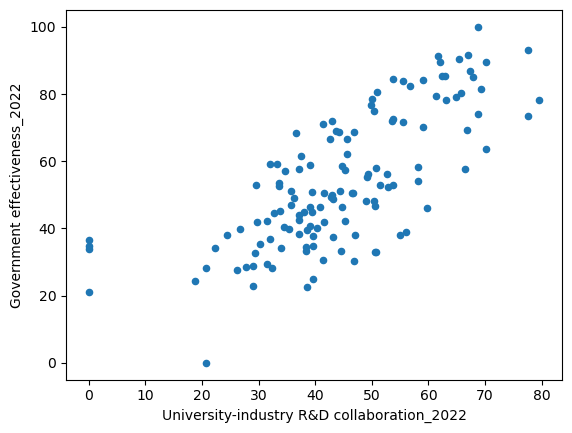

In [141]:
df2.plot('University-industry R&D collaboration_2022', 'Government effectiveness_2022', kind='scatter');

💡 **Вывод:** На графике видим несколько необычных точек, но в целом взаимосвязь носит линейный характер.

In [142]:
df2[['Creative goods and services_2022','Business environment_2022','Government effectiveness_2022']].\
corrwith(df2['University-industry R&D collaboration_2022'])
# коэффициенты корреляции Персона между признаком University-industry R&D collaboration_2022 и 3-мя другими 
# все признаки имеют распределение, близкое к нормальному

Creative goods and services_2022    0.544774
Business environment_2022           0.759305
Government effectiveness_2022       0.735465
dtype: float64

In [143]:
df2[['Creative goods and services_2022','Business environment_2022','Government effectiveness_2022']].\
corrwith(df2['University-industry R&D collaboration_2022']).sort_values()
# коэффициенты корреляции отсортированы по возрастанию

Creative goods and services_2022    0.544774
Government effectiveness_2022       0.735465
Business environment_2022           0.759305
dtype: float64

In [144]:
df2[['Creative goods and services_2022','Business environment_2022',
    'Government effectiveness_2022', 'University-industry R&D collaboration_2022']].corr()
# корреляционная матрица на основе 4 признаков

,Creative goods and services_2022,Business environment_2022,Government effectiveness_2022,University-industry R&D collaboration_2022
Creative goods and services_2022,1.000000,0.400947,0.687971,0.544774
Business environment_2022,0.400947,1.000000,0.674534,0.759305
Government effectiveness_2022,0.687971,0.674534,1.000000,0.735465
University-industry R&D collaboration_2022,0.544774,0.759305,0.735465,1.000000


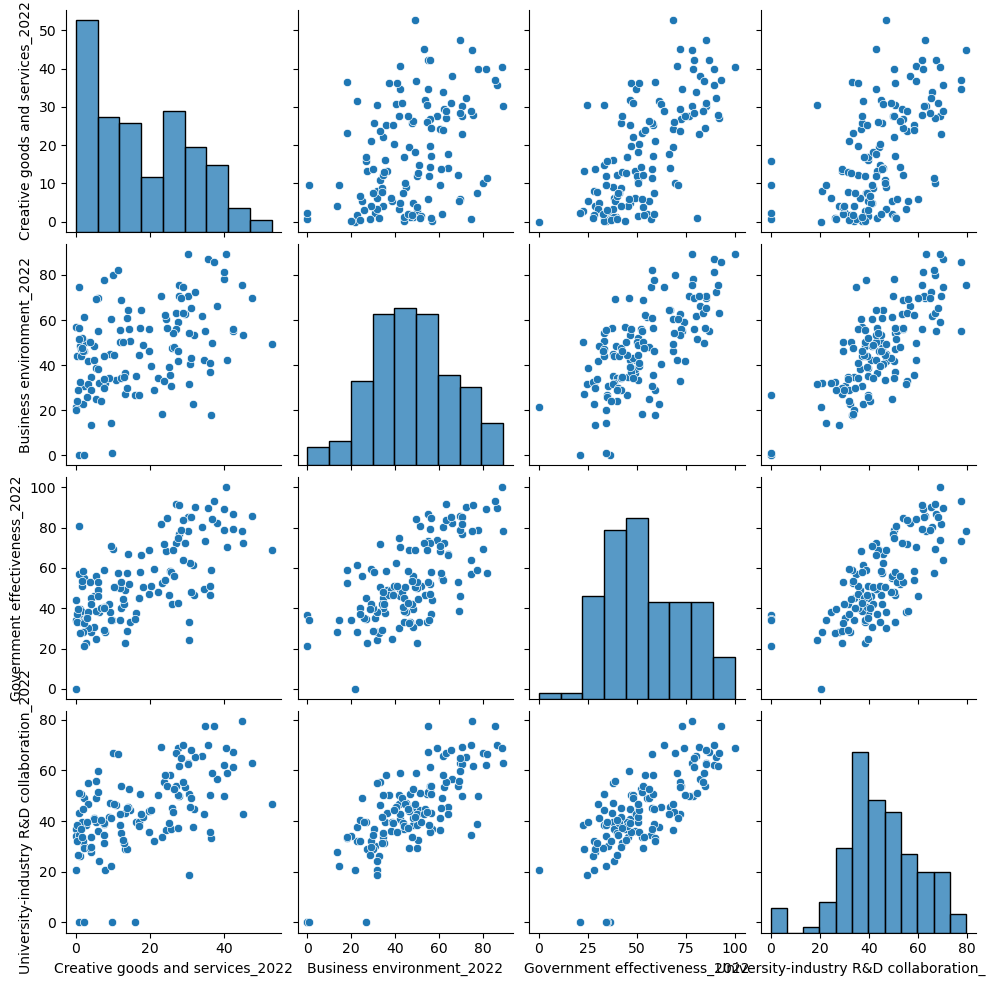

In [145]:
sns.pairplot(df2[['Creative goods and services_2022','Business environment_2022',
                 'Government effectiveness_2022', 'University-industry R&D collaboration_2022']]);
# матрица диаграмм рассеяния

In [146]:
df2[['Creative goods and services_2022','Business environment_2022',
    'Government effectiveness_2022', 'University-industry R&D collaboration_2022']].corr().stack()
# содержимое корреляционной матрицы представлено как одномерный ряд

Creative goods and services_2022            Creative goods and services_2022              1.000000
                                            Business environment_2022                     0.400947
                                            Government effectiveness_2022                 0.687971
                                            University-industry R&D collaboration_2022    0.544774
Business environment_2022                   Creative goods and services_2022              0.400947
                                            Business environment_2022                     1.000000
                                            Government effectiveness_2022                 0.674534
                                            University-industry R&D collaboration_2022    0.759305
Government effectiveness_2022               Creative goods and services_2022              0.687971
                                            Business environment_2022                     0.674534
          

In [147]:
df2[['Creative goods and services_2022','Business environment_2022',
    'Government effectiveness_2022', 'University-industry R&D collaboration_2022']].corr().stack().sort_values()
# результаты отсортированы

Creative goods and services_2022            Business environment_2022                     0.400947
Business environment_2022                   Creative goods and services_2022              0.400947
Creative goods and services_2022            University-industry R&D collaboration_2022    0.544774
University-industry R&D collaboration_2022  Creative goods and services_2022              0.544774
Business environment_2022                   Government effectiveness_2022                 0.674534
Government effectiveness_2022               Business environment_2022                     0.674534
Creative goods and services_2022            Government effectiveness_2022                 0.687971
Government effectiveness_2022               Creative goods and services_2022              0.687971
                                            University-industry R&D collaboration_2022    0.735465
University-industry R&D collaboration_2022  Government effectiveness_2022                 0.735465
Business e

💡 **Вывод:** Наиболее сильная корреляция наблюдается между университетско-промышленным сотрудничеством в сфере НИОКР и эффективностью государственного управления (0,735), а также между бизнес-средой и университетско-промышленным сотрудничеством (0,759), что указывает на ключевую роль институциональных и управленческих факторов в развитии инновационной экосистемы. Креативные товары и услуги также значительно связаны с эффективностью государства (0,688) и сотрудничеством науки и бизнеса (0,545), что подчеркивает зависимость креативного сектора от качества управления и инновационной инфраструктуры. В целом высокая степень корреляции между всеми переменными свидетельствует о системном характере их развития и взаимном усилении в рамках национальной экономики.

### Статистическая значимость коэффициента корреляции Пирсона

In [148]:
stats.pearsonr(df2['University-industry R&D collaboration_2022'].dropna(), 
               df2['Business environment_2022'].dropna())

PearsonRResult(statistic=np.float64(0.7593053875329313), pvalue=np.float64(5.056226771673642e-26))

In [149]:
print("Pearson's r:", stats.pearsonr(df2['University-industry R&D collaboration_2022'].dropna(), df2['Business environment_2022'].dropna())[0], 
       '    p-value:', stats.pearsonr(df2['University-industry R&D collaboration_2022'].dropna(), df2['Business environment_2022'].dropna())[1])

Pearson's r: 0.7593053875329313     p-value: 5.056226771673642e-26


Признаки **University-industry R&D collaboration** и **Business environment** являются числовыми, распределения их значений не отличаются от нормального. Поэтому для оценки взаимосвязи между ними был использован коэффициент корреляции Пирсона.

Нулевая гипотеза (H₀): взаимосвязь между сотрудничеством университетов и индустрии в области НИОКР и бизнес-средой отсутствует (r = 0).

Альтернативная гипотеза (H₁): между сотрудничеством университетов и индустрии в области НИОКР и бизнес-средой существует статистически значимая взаимосвязь (r ≠ 0).

💡 **Вывод:** 

1. Статистическая значимость взаимосвязи: поскольку p-value < 0.05, нулевая гипотеза отвергается, а альтернативная гипотеза принимается, что свидетельствует о статистически значимой взаимосвязи между рассматриваемыми признаками.
2. Направление взаимосвязи: коэффициент корреляции положительный, следовательно, между признаками наблюдается прямая взаимосвязь. Более благоприятная бизнес-среда ассоциируется с более высоким уровнем сотрудничества между университетами и индустрией в сфере НИОКР.
3. Сила взаимосвязи: коэффициент корреляции равен 0.76, следовательно, между признаками наблюдается сильная корреляция. 

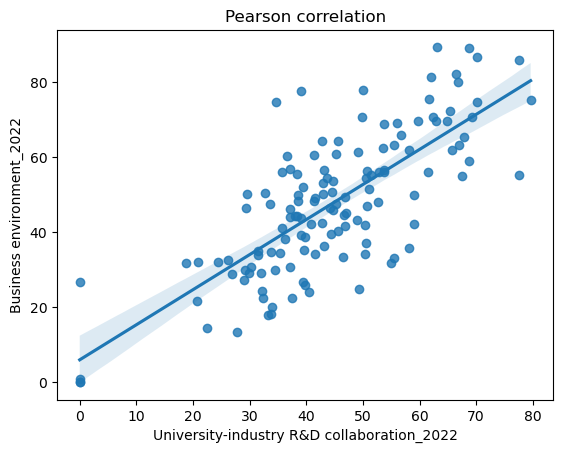

In [150]:
sns.regplot(df2, x = 'University-industry R&D collaboration_2022', 
            y = 'Business environment_2022').set_title('Pearson correlation');

### Коэффициент корреляции Спирмена и его статистическая значимость

In [151]:
stats.spearmanr(df2['Information and Communications Technology use_2022'].dropna(), 
                df2['High-tech manufacturing, %_2022'].dropna())

SignificanceResult(statistic=np.float64(0.6749691181222638), pvalue=np.float64(7.023352609224242e-19))

In [153]:
print("Spearman's ρ:", stats.spearmanr(
    df2['Information and Communications Technology use_2022'].dropna(),
    df2['High-tech manufacturing, %_2022'].dropna()
)[0], 
      '    p-value:', stats.spearmanr(
    df2['Information and Communications Technology use_2022'].dropna(),
    df2['High-tech manufacturing, %_2022'].dropna()
)[1])

Spearman's ρ: 0.6749691181222638     p-value: 7.023352609224242e-19


Признаки **Information and Communications Technology use** и **High-tech manufacturing, %** являются числовыми, но их распределения отличаются от нормального. Поэтому для оценки взаимосвязи между ними лучше рассчитать коэффициенты ранговой корреляции (Спирмена или Кендалла). Поскольку значения каждого признака в основном уникальны, и когда мы проранжируем страны по ним, мы не получим или получим небольшое количество связанных рангов, коэффициент корреляции Спирмена является предпочтительным.

Нулевая гипотеза (H₀): взаимосвязь между использованием информационно-коммуникационных технологий и высокотехнологичным производством отсутствует (r = 0).

Альтернативная гипотеза (H₁): между использованием информационно-коммуникационных технологий и высокотехнологичным производством существует статистически значимая взаимосвязь (r ≠ 0).

💡 **Вывод:** наблюдается статистически значимая положительная средняя корреляция.

In [154]:
df2[['Information and Communications Technology use_2022',
    'High-tech manufacturing, %_2022',
    'University-industry R&D collaboration_2022']].corr('spearman') 
# матрица коэффициентов корреляции Спирмена

,Information and Communications Technology use_2022,"High-tech manufacturing, %_2022",University-industry R&D collaboration_2022
Information and Communications Technology use_2022,1.000000,0.674969,0.616121
"High-tech manufacturing, %_2022",0.674969,1.000000,0.544839
University-industry R&D collaboration_2022,0.616121,0.544839,1.000000


### Коэффициент корреляции Кендалла и его статистическая значимость

In [155]:
df2['Income'].value_counts()

Income
middle income    72
high income      52
low income       15
Name: count, dtype: int64

In [156]:
df2['Income']=df2['Income'].replace('low income', 1)
df2['Income']=df2['Income'].replace('middle income', 2)
df2['Income']=df2['Income'].replace('high income', 3)
df2['Income'].value_counts()
# перекодирование признака из текстового в числовой

Income
2    72
3    52
1    15
Name: count, dtype: int64

In [157]:
df3 = df2.dropna(subset=['Income', 'University-industry R&D collaboration_2022'])
# удаление наблюдений, содержащих пропуски хотя бы по одному из анализируемых признаков
stats.kendalltau(df3.Income, df3['University-industry R&D collaboration_2022'])

SignificanceResult(statistic=np.float64(0.43833419909418553), pvalue=np.float64(2.484630881829298e-10))

**University-industry R&D collaboration_2022** — это числовой признак, распределение его значений отличается от нормального. **Income** — это категориальный прихнак с порядковой шкалой измерения. Поэтому для оценки взаимосвязи между ними лучше рассчитать коэффициенты ранговой корреляции (Спирмена или Кендалла). Поскольку большинство значений признака Income не являются уникальными, при ранжировании стран по этому признаку, получится много связанных рангов, коэффициент корреляции Кендалла является предпочтительным.

💡 **Вывод:** Между признаками выявлена статистически значимая прямая слабая корреляция.

In [158]:
df2[['Income','University-industry R&D collaboration_2022',
    'Information and Communications Technology use_2022']].corr('kendall') 
# матрица коэффициентов корреляции Кендалла

,Income,University-industry R&D collaboration_2022,Information and Communications Technology use_2022
Income,1.000000,0.438334,0.717396
University-industry R&D collaboration_2022,0.438334,1.000000,0.437374
Information and Communications Technology use_2022,0.717396,0.437374,1.000000


### Точечно-бисериальная корреляция

Рассчитывается когда один признак числовой, а второй бинарный.

In [159]:
df4 = df2.dropna(subset=['University-industry R&D collaboration_2022', 'High income'])
pb, pval = pointbiserialr(df4['University-industry R&D collaboration_2022'], df4['High income'])
print(f'Точечно-бисериальная корреляция: {np.round(pb, 4)}, pvalue = {np.round(pval, 4)}')

Точечно-бисериальная корреляция: 0.5275, pvalue = 0.0


💡 **Вывод:** Наблюдается статистически значимая средняя корреляция.

### Коэффициент Фи

Подходит для оценки взаимосвязи связи между двумя бинарными признаками. 

In [160]:
def phi_corr(data, x, y):
    t = pd.crosstab(data[x], data[y]).values
    chi2, p, _, _ = chi2_contingency(t, correction=False)
    phi = np.sqrt(chi2 / t.sum())
    return phi * np.sign(t[0,0]*t[1,1] - t[0,1]*t[1,0]), p

phi, p = phi_corr(df2, "High income", "Least developed countries")
print(f"phi = {phi:.3f}, p-value = {p:.4g}")

phi = -0.371, p-value = 1.23e-05


💡 **Вывод:** Наблюдается статистически значимая обратная слабая корреляция.

### Частная корреляция

Рассчитаем парный коэффициент корреляции между сотрудничеством университетов и промышленности в сфере НИОКР и бизнес-средой в 2022 году.

In [161]:
stats.pearsonr(df2['University-industry R&D collaboration_2022'].dropna(), 
               df2['Business environment_2022'].dropna())

PearsonRResult(statistic=np.float64(0.7593053875329313), pvalue=np.float64(5.056226771673642e-26))

Теперь проконтролируем влияние на эту корреляцию признака **High-tech manufacturing, %_2022**

In [162]:
pg.partial_corr(data=df2, x='University-industry R&D collaboration_2022', 
                y='Business environment_2022', covar='High-tech manufacturing, %_2022')
# К-т Пирсона

,n,r,CI95,p_val
pearson,132,0.745422,"[0.66, 0.81]",1.773242e-24


In [163]:
pg.partial_corr(data=df2, x='Business environment_2022', y='University-industry R&D collaboration_2022', 
                covar='High-tech manufacturing, %_2022', method = 'spearman')
# К-т Спирмена

,n,r,CI95,p_val
spearman,132,0.702864,"[0.6, 0.78]",8.172177e-21


💡 **Вывод:** Можно сделать вывод, что корреляция между сотрудничеством университетов и промышленности в области НИОКР и бизнес-средой существенно не изменилась после того, как мы исключили влияние на их корреляцию признака, характеризующего высокотехнологичное производство.

### Визуализация корреляций

In [164]:
corr = df2[['Creative goods and services_2022','Business environment_2022',
           'Government effectiveness_2022', 
            'University-industry R&D collaboration_2022']].dropna().corr(numeric_only=True)
corr.style.background_gradient(cmap='coolwarm')

,Creative goods and services_2022,Business environment_2022,Government effectiveness_2022,University-industry R&D collaboration_2022
Creative goods and services_2022,1.000000,0.400947,0.687971,0.544774
Business environment_2022,0.400947,1.000000,0.674534,0.759305
Government effectiveness_2022,0.687971,0.674534,1.000000,0.735465
University-industry R&D collaboration_2022,0.544774,0.759305,0.735465,1.000000


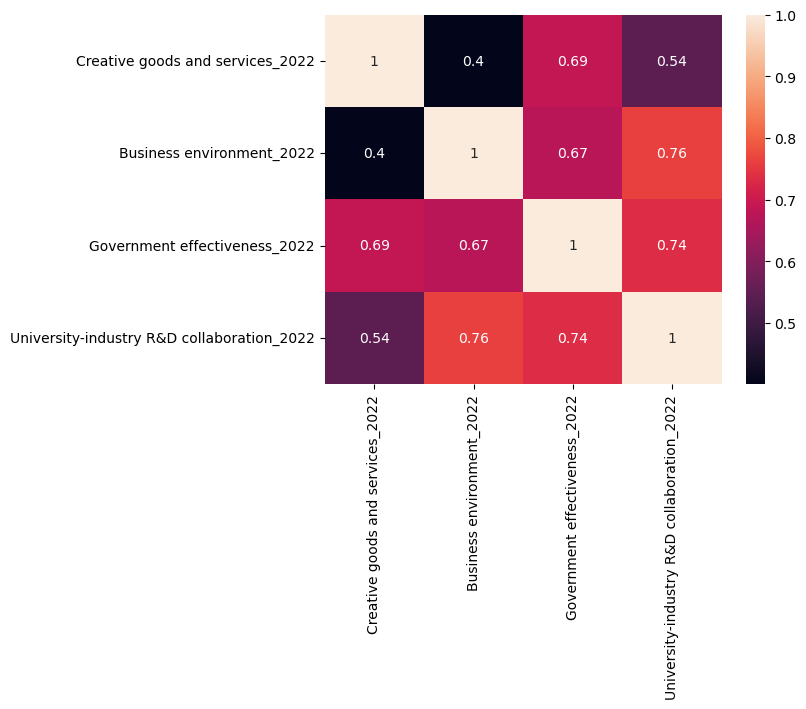

In [165]:
sns.heatmap(df2[['Creative goods and services_2022','Business environment_2022',
                'Government effectiveness_2022', 'University-industry R&D collaboration_2022']]
            .corr(), annot=True); # тепловая карта с метками значений

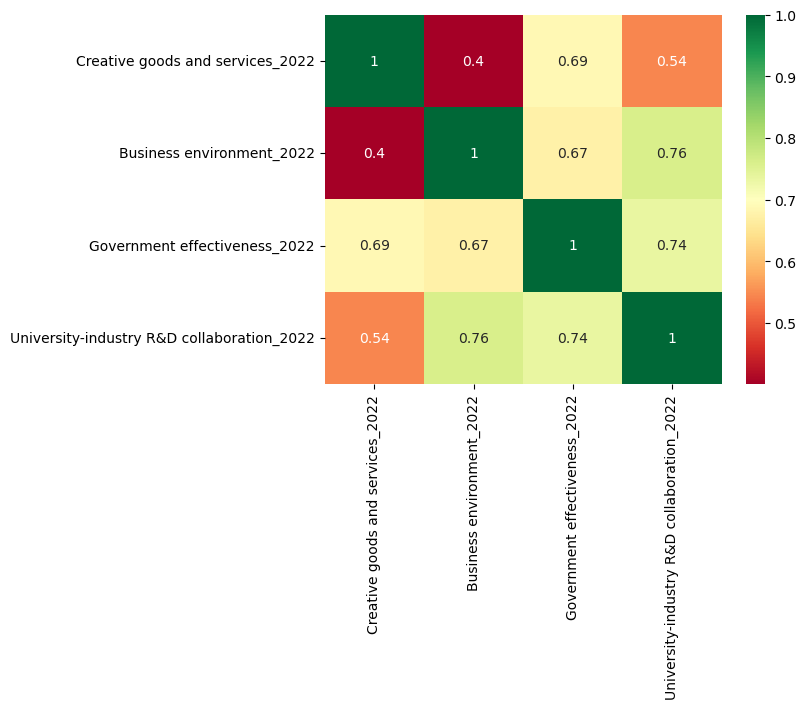

In [166]:
sns.heatmap(df2[['Creative goods and services_2022','Business environment_2022',
                'Government effectiveness_2022', 
                'University-industry R&D collaboration_2022']].corr(), annot=True, cmap='RdYlGn');
# другая цветовая шкала

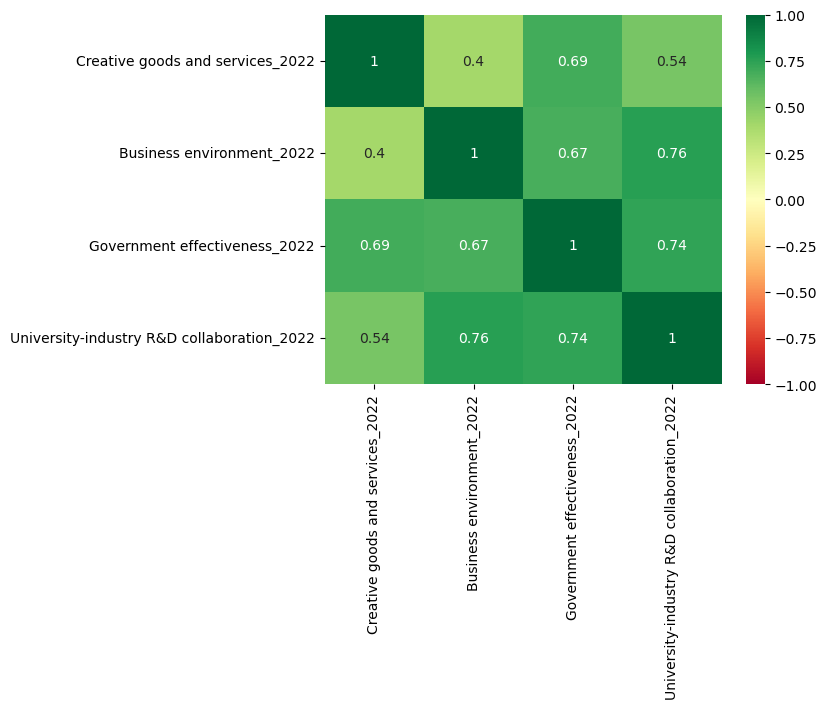

In [167]:
sns.heatmap(df2[['Creative goods and services_2022','Business environment_2022',
                 'Government effectiveness_2022', 
                 'University-industry R&D collaboration_2022']].corr(), annot=True, cmap='RdYlGn', vmax=1, vmin=-1); 
# заданы минимальные и максимальные значения шкалы

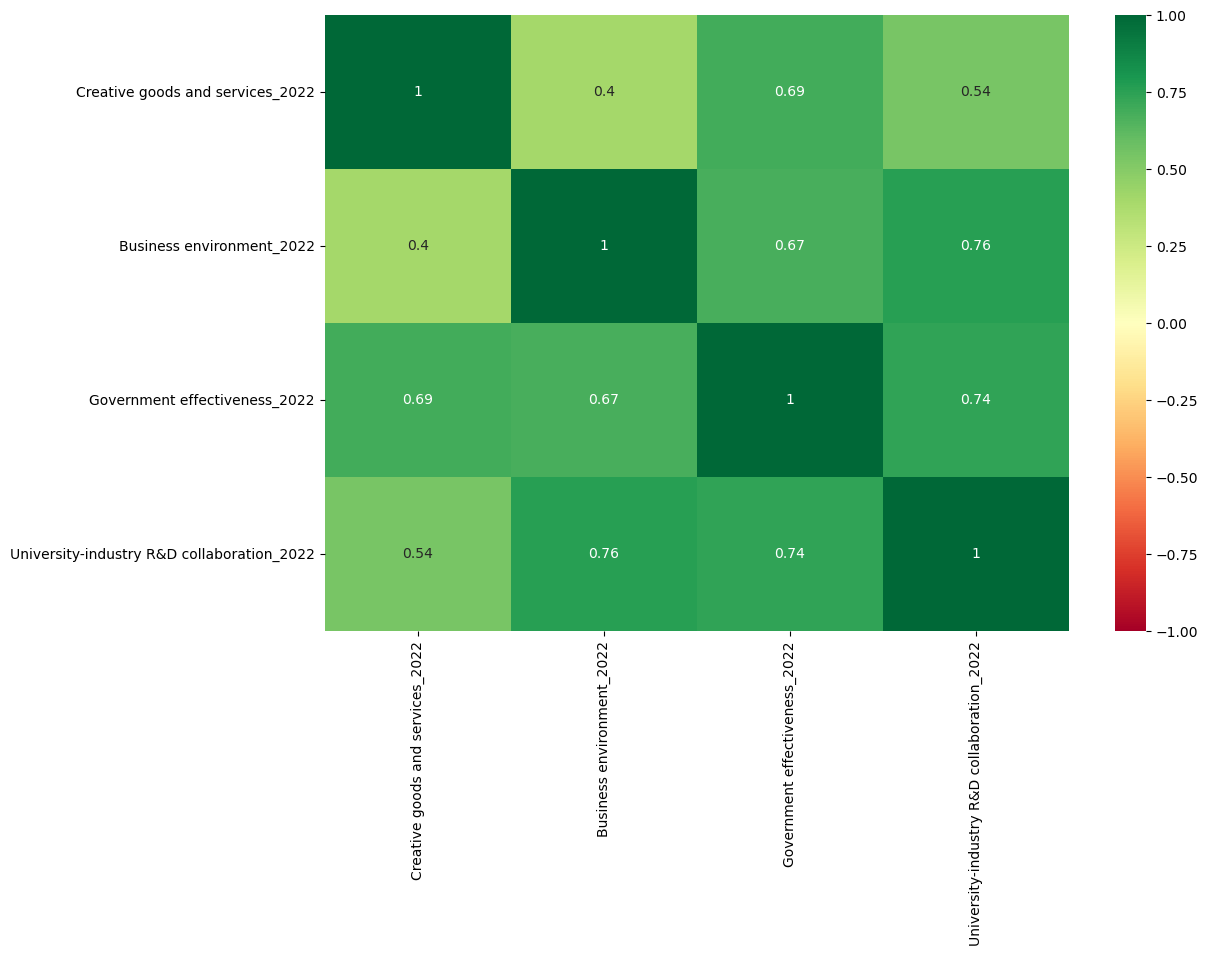

In [168]:
plt.figure(figsize=(12,8))  # скорректирован размер
sns.heatmap(df2[['Creative goods and services_2022',
                 'Business environment_2022','Government effectiveness_2022', 
                 'University-industry R&D collaboration_2022']].corr(), annot=True, cmap='RdYlGn', vmax=1, vmin=-1);

In [170]:
df1 = df2[['Creative goods and services_2022','Business environment_2022',
          'Government effectiveness_2022', 'University-industry R&D collaboration_2022']]
rho = df1.corr()
pval = df1.corr(method=lambda x, y: stats.pearsonr(x, y)[1]) - np.eye(*rho.shape)
p = pval.applymap(lambda x: ''.join(['*' for t in [.1, .05, .01] if x<=t]))
rho.round(2).astype(str) + p

,Creative goods and services_2022,Business environment_2022,Government effectiveness_2022,University-industry R&D collaboration_2022
Creative goods and services_2022,1.0***,0.4***,0.69***,0.54***
Business environment_2022,0.4***,1.0***,0.67***,0.76***
Government effectiveness_2022,0.69***,0.67***,1.0***,0.74***
University-industry R&D collaboration_2022,0.54***,0.76***,0.74***,1.0***


Звездочками помечена статистическая значимость: * - p < 0.1; ** - p < 0.05; *** - p < 0.01